# ♟️ Lichess Bulmaca Zorluğu Tahmini — v3: İnsan Hamle Modeli (Maia-2) ile Literatürü Yakalamak

**Ders:** Bilgisayar Mühendisliğinde Gelişmeler 2 · **Hazırlayan:** Hamza Bilici

**Amaç:** Bulmacanın Glicko-2 zorluk puanını (`Rating`) yalnızca `FEN` ve `Moves`'tan tahmin etmek (regresyon, ölçüt RMSE; yarışmalarla karşılaştırma için MSE de raporlanır).

### v2'de neredeyiz?
v2 notebook'u 37 elle tasarlanmış öznitelik + Optuna ile ayarlanmış LightGBM / XGBoost / CatBoost + Stacking ile hold-out testte **RMSE 295,8** (MSE ≈ 87.500, R² 0,614) verdi. Hatanın yaklaşık yarısı ≥ 1700 puanlı zor bulmacalardan geliyordu.

Literatürdeki en iyi çözümlerin hepsinde ortak bir bileşen var: **insan hamle modeli Maia**. 2024 birincisi Maia gömümlerini kullandı. 2025'te organizatörler her bulmaca için Maia-2'nin "bu seviyedeki bir insan çözer mi?" olasılıklarını (11 Elo seviyesi × rapid/blitz = 22 sütun) hazır olarak verdi. Björkqvist'in (2025) ablasyonunda bu bilgi çıkarılınca hata %49 artıyor. Bizim v2 modelimizde bu bilgi yok. **v3'ün işi bu eksiği kapatmak.**

### Bu notebook ne yapıyor?
| # | Adım | Neden |
|---|---|---|
| 1 | v2 ile **aynı veri, aynı %80 / %20 bölme, aynı 5 katman** | Sonuçlar v2 ile birebir karşılaştırılabilir |
| 2 | 37 el yapımı öznitelik (v2 kodu, değişmedi) | v2 çıktısı eklendiyse diskten okunur |
| 3 | **Maia-2 öznitelikleri:** her oyuncu hamlesinde 11 Elo seviyesi × 2 model (rapid, blitz) için "doğru hamleyi oynama olasılığı" ve bunlardan türetilen özetler (62 öznitelik) | Literatürdeki en güçlü tekil sinyal |
| 4 | **Ablasyon:** A = sadece el yapımı (v2), B = sadece Maia-2, C = ikisi birlikte | Kazancın nereden geldiğini ölçmek |
| 5 | v2'de Optuna'nın bulduğu **en iyi parametreler** kullanılır (isteğe bağlı yeniden arama: `RETUNE=True`) | Uzun aramayı tekrarlamadan adil karşılaştırma |
| 6 | Voting (SLSQP) ve Stacking (Ridge) yalnızca OOF tahminleriyle | v2 ile aynı kurallar |
| 7 | **Eşleştirilmiş karşılaştırma:** katman katman fark + hold-out üzerinde bootstrap güven aralığı | "C, A'dan gerçekten iyi mi, yoksa şans mı?" sorusunun cevabı |
| 8 | Sızıntı denetçisi, checkpoint'ler, 300 DPI grafikler, liderlik tablosu | v2 ile aynı kurallar |

### Maia-2 nedir, neden sızıntı değildir?
Maia-2 (Tang vd., NeurIPS 2024), Lichess'teki **insan oyunlarından** eğitilmiş bir sinir ağıdır. Bir pozisyon ve oyuncu seviyesi verildiğinde, o seviyedeki bir insanın her yasal hamleyi oynama olasılığını tahmin eder. Satranç motorlarının aksine en iyi hamleyi değil, **insanların gerçekte oynadığı hamleyi** öğrenmiştir. Bu yüzden "bu bulmacayı 1200'lük bir oyuncu çözer mi?" sorusuna doğrudan cevap verir.
- Model yalnızca `FEN` ve `Moves`'tan elde edilen pozisyonları görür; bulmaca puanlarını, deneme sayılarını veya temalarını **hiç görmedi**.
- Yarışma kurallarına uygundur: IEEE BigData Cup 2024 ve FedCSIS 2025'te dış modeller serbestti; 2025'te organizatörler bu olasılıkları kendileri dağıttı.
- Ağırlıklar dondurulmuştur (eğitim yok). Her bulmaca kendi başına işlenir; satırlar arası istatistik öğrenilmez.

### Çalıştırma (Kaggle)
- **Accelerator: GPU T4 x2** (P100 seçmeyin: güncel PyTorch sürümleri P100'ü desteklemiyor). Maia-2 CPU'da 500 bin bulmaca için saatler sürer; GPU yoksa notebook ana eğitimden önce açık bir hata ile durur.
- **Internet: açık** (`python-chess` ve `maia2` kurulumu, Maia-2 ağırlıklarının Google Drive'dan indirilmesi).
- **Önerilen:** *Add Input → Your Work* ile v2 notebook'unun çıktısını ekleyin. O zaman el yapımı öznitelikler ve A deneyinin modelleri v2'den okunur (yaklaşık 50 dakika kazanç). Eklenmezse her şey yeniden hesaplanır; sonuç aynı olur.
- **Tahmini süre:** Maia-2 öznitelikleri 20–40 dk (GPU'ya bağlı; ilerleme ve kalan süre yazdırılır), B deneyi ~5 dk, C deneyi ~1,5 saat (99 öznitelikle 3 model × 5 katman, CPU). v2 çıktısı eklenmezse +50 dk. Uzun çalışma için **Save Version → Save & Run All (Commit)** önerilir.
- Oturum koparsa notebook'u yeniden çalıştırmak yeter: Maia-2 öznitelikleri 50 binlik parçalar halinde, modeller `.joblib` olarak kaydedilir.

### İçindekiler
1. Kurulum · 2. Ayarlar · 3. Veri · 4. El yapımı öznitelikler · 5. Maia-2 öznitelikleri · 6. Sızıntı denetçisi ve bölme · 7. Ön işleme · 8. Modeller ve parametreler · 9. CV motoru ve checkpoint · 10. Ensemble · 11. İstatistiksel karşılaştırma · 12. Grafikler · 13. Liderlik tablosu · 14. Boru hattı · 15. Smoke test · 16. Ana eğitim · 17. Sonuçlar · 18. Yorumlama ve sonraki adım

## 1. Kurulum
- `python-chess`: Kaggle'da hazır gelmiyor.
- `maia2==0.10.0`: Paket eski `torch` / `numpy` / `pandas` sürümlerine sabitlenmiş bağımlılıklar istiyor. Kaggle'ın kendi kütüphanelerini bozmamak için `--no-deps` ile kurulur; gerçekten ihtiyaç duyduğu küçük paketler (`einops`, `pyzstd`, `gdown`) ayrıca kurulur.
- `TargetEncoder` için scikit-learn ≥ 1.3 kontrolü.

In [1]:
%pip install -q python-chess
%pip install -q --no-deps maia2==0.10.0
%pip install -q einops pyzstd gdown
# TargetEncoder için scikit-learn >= 1.3 gerekir; eski imajlarda yükselt (sklearn henüz içe aktarılmadığı için yeniden başlatma gerekmez)
import importlib.metadata as _md
from packaging.version import Version
if Version(_md.version("scikit-learn")) < Version("1.3"):
    %pip install -q -U "scikit-learn>=1.3"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
maia2 0.10.0 requires chess==1.10.0, but you have chess 1.11.2 which is incompatible.
maia2 0.10.0 requires einops==0.8.0, but you have einops 0.8.2 which is incompatible.
maia2 0.10.0 requires gdown==5.2.0, but you have gdown 5.2.2 which is incompatible.
maia2 0.10.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
maia2 0.10.0 requires pyzstd==0.15.9, but you have pyzstd 0.20.0 which is incompatible.
maia2 0.10.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
maia2 0.10.0 requires torch==2.8.0, 

In [2]:
import os, glob, time, shutil, hashlib, warnings
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import chess
import torch
import maia2
from maia2 import model as maia_model
from maia2.utils import get_all_possible_moves, create_elo_dict, mirror_move, board_to_tensor
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from optuna.trial import TrialState, FixedTrial
from joblib import Parallel, delayed, dump, load
from scipy.optimize import minimize

import sklearn
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, TargetEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, roc_auc_score,
                             average_precision_score, f1_score, brier_score_loss, log_loss,
                             roc_curve, precision_recall_curve, confusion_matrix)
import lightgbm as lgb
import xgboost as xgb
import catboost as cb

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
MAVI, TURUNCU, GRI = "#2a78d6", "#eb6834", "#8a8a8a"
RENK = {"A": GRI, "B": TURUNCU, "C": MAVI}                    # deney renkleri: A = v2 (gri), B = sadece Maia, C = yeni model

CIHAZ = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(" | ".join(f"{m.__name__} {m.__version__}" for m in (np, pd, sklearn, lgb, xgb, cb, optuna, chess, torch, maia2)))
print("Maia-2 cihazı:", torch.cuda.get_device_name(0) if CIHAZ.type == "cuda" else "CPU (GPU bulunamadı)")

numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | lightgbm 4.6.0 | xgboost 3.4.1 | catboost 1.2.10 | optuna 5.0.0 | chess 1.11.2 | torch 2.11.0+cu128 | maia2 0.10.0
Maia-2 cihazı: Tesla T4


## 2. Ayarlar (`Config`)
v2'deki bütün ayarlar aynen korunur; yeni ayarlar aşağıda. `PROBLEM_TYPE` değiştirildiğinde bölme, metrikler, modeller, meta-model ve grafikler yine kendiliğinden uyarlanır (Maia-2 öznitelikleri hedeften bağımsızdır).

| Yeni ayar | Değer | Gerekçe |
|---|---|---|
| `RETUNE` | `False` | v2'nin Optuna'da (30 deneme) bulduğu parametreler kullanılır. `True` olursa her model ve deney için yeni bir Optuna araması açılır; ilk deneme v2 parametreleridir (sıcak başlangıç), CatBoost `depth` üst sınırı 8'den 10'a çıkar |
| `STUDY_VERSION` | `"v3"` | v3 checkpoint'leri v2'ninkilerle karışmaz |
| `V2_REUSE` | `True` | v2 çıktısı eklendiyse el yapımı öznitelikler ve A modelleri oradan okunur (önce birebir aynı bölme olduğu doğrulanır) |
| `MAIA_TYPES` | rapid, blitz | Maia-2'nin iki yayımlanmış modeli; 2025 yarışmasında da ikisi kullanıldı |
| `MAIA_BATCH`, `MAIA_CHUNK` | 1024, 50.000 | GPU yığın boyutu; checkpoint parçası (bulmaca) |
| `MAIA_CPU_MAX` | 20.000 | GPU yoksa en fazla bu kadar bulmaca işlenir (smoke test için yeterli) |
| `N_BOOT` | 1000 | Eşleştirilmiş bootstrap tekrar sayısı |
| `BOOSTING_GPU` | `False` | `True`: XGBoost ve CatBoost GPU'da eğitilir (çok daha hızlı, sayısal sonuçlar CPU'dakinden biraz farklı olur) |

In [3]:
@dataclass(frozen=True)
class Config:
    # --- Kullanıcı girdileri ---
    PROBLEM_TYPE: str = "regression"                 # 'regression' veya 'classification' (ikili sınıflandırma)
    DATA_PATH: str = "/kaggle/input/datasets/hamzabilici/lichess-db/puzzles_500k.parquet"
    TARGET_COL: str = "Rating"
    DROP_COLS: tuple = ("PuzzleId", "GameUrl", "RatingDeviation", "Popularity",
                        "NbPlays", "Themes", "OpeningTags", "DailyDate")   # kimlik + sızıntı riski taşıyan sütunlar
    N_SPLITS: int = 5
    N_TRIALS: int = 30
    # --- Projeye özgü ---
    RAW_COLS: tuple = ("FEN", "Moves")               # öznitelikler bunlardan üretilir, sonra modelden çıkarılır
    BAND_EDGES: tuple = (0, 1000, 1400, 1700, 4000)  # puan bantları (bant bazlı hata analizi için)
    # --- Bölme ve tekrar üretilebilirlik (v2 ile aynı olmalı) ---
    TEST_SIZE: float = 0.20
    SEED: int = 42
    # --- Hiperparametreler ---
    RETUNE: bool = False                             # False: v2'nin en iyi parametreleri; True: v2'den başlayan yeni Optuna araması
    TUNE_SAMPLE: int = 80_000
    TUNE_LR: float = 0.10
    TUNE_MAX_TREES: int = 2_000
    STUDY_VERSION: str = "v3"
    # --- Nihai eğitim ---
    FINAL_LR: float = 0.05
    FINAL_MAX_TREES: int = 10_000
    EARLY_STOP: int = 100
    ES_FRACTION: float = 0.10
    SMOKE_TREES: int = 0                             # > 0 ise bütün ağaç sayıları bu değere sabitlenir (smoke test)
    BOOSTING_GPU: bool = False                       # True: XGBoost ve CatBoost GPU'da eğitilir
    # --- Ön işleme ---
    LOW_CARD_MAX: int = 10                           # ≤ 10 benzersiz değer: one-hot, fazlası: target encoding
    # --- Deneyler ---
    MODELS: tuple = ("LightGBM", "XGBoost", "CatBoost")   # A ve C deneylerinin modelleri
    B_MODELS: tuple = ("LightGBM",)                  # B (sadece Maia-2) deneyinin modeli
    N_BOOT: int = 1000
    # --- Öznitelik sürümleri (kod değişirse sürüm artırılır, eski önbellek kullanılmaz) ---
    FEATURE_VERSION: str = "o1"                      # o1 = v2'deki 37 öznitelik kodu
    MAIA_VERSION: str = "m1"
    # --- Maia-2 ---
    MAIA_TYPES: tuple = ("rapid", "blitz")
    MAIA_DIR: str = "/kaggle/working/maia2_models"   # ağırlıklar (smoke test klasörünün dışında: bir kez indirilir)
    MAIA_BATCH: int = 1024
    MAIA_CHUNK: int = 50_000
    MAIA_CPU_MAX: int = 20_000
    # --- Önceki notebook (v2) ---
    V2_REUSE: bool = True
    V2_TAG: str = "v1"                               # v2 checkpoint dosyalarındaki sürüm adı
    # --- Ortam ---
    INPUT_DIR: str = "/kaggle/input"
    WORK_DIR: str = "/kaggle/working"
    N_JOBS: int = -1

    @property
    def is_clf(self):
        # Sınıflandırma mı?
        return self.PROBLEM_TYPE == "classification"

    @property
    def ckpt_dir(self):
        # Öznitelik ve model checkpoint klasörü
        return os.path.join(self.WORK_DIR, "checkpoints")

    @property
    def plot_dir(self):
        # 300 DPI grafiklerin klasörü
        return os.path.join(self.WORK_DIR, "plots")

    @property
    def optuna_db(self):
        # Optuna SQLite checkpoint adresi (sqlite:////kaggle/working/optuna_studies.db)
        return "sqlite:///" + os.path.join(self.WORK_DIR, "optuna_studies.db")

    @property
    def metric_name(self):
        # Raporlarda kullanılan ölçüt adı
        return "ROC-AUC" if self.is_clf else "RMSE"

    def tree_limit(self, final):
        # Smoke testte sabit 10 ağaç; aksi halde arama / nihai eğitim sınırları
        if self.SMOKE_TREES > 0:
            return self.SMOKE_TREES
        return self.FINAL_MAX_TREES if final else self.TUNE_MAX_TREES


CFG = Config()
assert CFG.PROBLEM_TYPE in ("regression", "classification"), "PROBLEM_TYPE 'regression' veya 'classification' olmalı"
print(f"Problem: {CFG.PROBLEM_TYPE} | Hedef: {CFG.TARGET_COL} | Ölçüt: {CFG.metric_name} | {CFG.N_SPLITS} katman | "
      f"Parametreler: {'yeni Optuna araması (' + str(CFG.N_TRIALS) + ' deneme)' if CFG.RETUNE else 'v2 en iyi parametreleri'} | "
      f"Maia-2: {', '.join(CFG.MAIA_TYPES)}")

Problem: regression | Hedef: Rating | Ölçüt: RMSE | 5 katman | Parametreler: v2 en iyi parametreleri | Maia-2: rapid, blitz


## 3. Veri yükleme ve doğrulama
v2 ile aynı: dosya yoksa `/kaggle/input` altındaki bütün dosyaları listeleyen `FileNotFoundError`, hedef sütun yoksa mevcut sütunları gösteren `KeyError`; hedefi eksik satırlar silinir. Ek olarak `_girdi_ara` yardımcısı, notebook'a eklenmiş girdiler (v2 çıktısı, Maia-2 ağırlıkları) arasında dosya arar.

In [4]:
def _girdi_ara(cfg, desen):
    # /kaggle/input altında (eklenmiş veri setleri ve notebook çıktıları dahil) dosya adına göre arar
    return sorted(p for p in glob.glob(os.path.join(cfg.INPUT_DIR, "**", desen), recursive=True) if os.path.isfile(p))


def veri_yukle(cfg):
    # Gerçek Kaggle verisini okur; dosya yolu, hedef sütun ve eksik hedef kontrollerini yapar
    if not os.path.isfile(cfg.DATA_PATH):
        mevcut = _girdi_ara(cfg, "*")
        liste = "\n".join(f"  - {p}" for p in mevcut) or "  (hiç dosya yok — notebook'a veri seti eklenmiş mi?)"
        raise FileNotFoundError(f"DATA_PATH bulunamadı: {cfg.DATA_PATH}\n{cfg.INPUT_DIR} altındaki mevcut dosyalar:\n{liste}")

    df = pd.read_parquet(cfg.DATA_PATH) if cfg.DATA_PATH.endswith(".parquet") else pd.read_csv(cfg.DATA_PATH)

    if cfg.TARGET_COL not in df.columns:
        raise KeyError(f"Hedef sütun '{cfg.TARGET_COL}' bulunamadı. Mevcut sütunlar: {list(df.columns)}")
    eksik_ham = [c for c in cfg.RAW_COLS if c not in df.columns]
    if eksik_ham:
        raise KeyError(f"Öznitelik üretimi için gereken sütun(lar) yok: {eksik_ham}. Mevcut sütunlar: {list(df.columns)}")

    n_eksik = int(df[cfg.TARGET_COL].isna().sum())
    if n_eksik:
        df = df.dropna(subset=[cfg.TARGET_COL])
    df = df.reset_index(drop=True)
    print(f"Veri: {len(df):,} satır × {df.shape[1]} sütun | hedefi eksik olduğu için silinen satır: {n_eksik}")
    return df


df_ham = veri_yukle(CFG)
if "RatingDeviation" in df_ham.columns:
    print(f"Puan güvenilirliği kontrolü: RatingDeviation en fazla {df_ham['RatingDeviation'].max()} (filtre: ≤ 90)")
display(df_ham[CFG.TARGET_COL].describe().round(1).to_frame().T)

Veri: 500,000 satır × 11 sütun | hedefi eksik olduğu için silinen satır: 0
Puan güvenilirliği kontrolü: RatingDeviation en fazla 90 (filtre: ≤ 90)


,count,mean,std,min,25%,50%,75%,max
Rating,500000.0,1500.5,475.9,399.0,1130.0,1469.0,1854.0,2969.0


## 4. El yapımı öznitelikler (v2'deki 37 öznitelik, kod değişmedi)
Gruplar: A. uzunluk · B. doğru ilk hamle · C. çözüm dizisi · D. materyal · E. pozisyon / taktik · F. çözüm boyunca aday kalabalığı. Ayrıntılı açıklama v2 notebook'unda.

**Önbellek düzeltmesi (v2 denetiminden):** v2'de önbellek dosyasının adı yalnızca verinin özetinden üretiliyordu; öznitelik kodu değişse bile eski dosya okunabilirdi. Artık dosya adında `FEATURE_VERSION` da var. v2 çıktısı eklendiyse aynı koddan (`o1`) üretilmiş eski dosya bulunur, satır indeksleri ve sütunları kontrol edilerek kullanılır.

In [5]:
PARCA_DEGER = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}
EVRE_AGIRLIK = {chess.KNIGHT: 1, chess.BISHOP: 1, chess.ROOK: 2, chess.QUEEN: 4}
TAS_AD = {chess.PAWN: "Piyon", chess.KNIGHT: "At", chess.BISHOP: "Fil", chess.ROOK: "Kale", chess.QUEEN: "Vezir", chess.KING: "Sah"}

OZNITELIK_ADLARI = [
    # A. Uzunluk
    "cozum_uzunlugu",
    # B. Doğru ilk hamle
    "ilk_sah", "ilk_alma", "ilk_tas", "ilk_geri", "ilk_mesafe",
    # C. Çözüm dizisi
    "cozum_sah", "cozum_alma", "cozum_sessiz", "sessiz_oran", "terfi_var", "mat_bitis", "cozum_geri",
    # D. Materyal
    "materyal_bas", "net_kazanc", "en_buyuk_dusus", "ilk_alinan_deger", "ilk_hedef_saldirida", "ilk_hedef_korunuyor",
    # E. Pozisyon / taktik
    "yasal_hamle", "sah_secenegi", "alma_secenegi", "aday_kalabaligi", "rakip_asili", "cozen_asili", "rakip_acmaz",
    "rakip_sah_cevre_saldiri", "rakip_sah_kacis", "cozen_sah_altinda", "evre_puani", "rakip_ilk_alma",
    # F. Çözüm boyunca aday kalabalığı
    "aday_toplam", "aday_max", "aday_ort", "yasal_ort", "rakip_secenek_ort", "rakip_zorunlu",
]


def _materyal(tahta, renk):
    """Renk açısından materyal farkı (P=1, A/F=3, K=5, V=9)."""
    return sum(PARCA_DEGER[t.piece_type] * (1 if t.color == renk else -1) for t in tahta.piece_map().values())


def _hamle_turu(tahta, hamle):
    """0 = sessiz, 1 = taş alma, 2 = şah çekme (şah önceliklidir)."""
    return 2 if tahta.gives_check(hamle) else (1 if tahta.is_capture(hamle) else 0)


def bulmaca_oznitelikleri(fen, moves):
    """Bir bulmacanın FEN + Moves bilgisinden 37 sayısal/kategorik öznitelik üretir (durumsuz, satır bazlı)."""
    tahta = chess.Board(fen)
    h = moves.split()
    rakip_hamle = chess.Move.from_uci(h[0])
    rakip_ilk_alma = int(tahta.is_capture(rakip_hamle))
    tahta.push(rakip_hamle)                                   # oyuncunun gördüğü pozisyon
    cozen, rakip = tahta.turn, not tahta.turn
    ileri = 1 if cozen == chess.WHITE else -1
    uzunluk = len(h) // 2
    dogru = chess.Move.from_uci(h[1])

    def geri_mi(m):
        # Hamle çözenin kendi tarafına doğru mu gidiyor?
        return int((chess.square_rank(m.to_square) - chess.square_rank(m.from_square)) * ileri < 0)

    # B. Doğru ilk hamle
    ilk_sah, ilk_alma = int(tahta.gives_check(dogru)), int(tahta.is_capture(dogru))
    ilk_tas = TAS_AD[tahta.piece_type_at(dogru.from_square)]
    ilk_geri, ilk_mesafe = geri_mi(dogru), chess.square_distance(dogru.from_square, dogru.to_square)

    # E. Pozisyon / taktik (oyuncunun gördüğü tahta)
    yasal = list(tahta.legal_moves)
    turler = [_hamle_turu(tahta, m) for m in yasal]
    rakip_asili = cozen_asili = rakip_acmaz = 0
    evre = 0
    for kare, tas in tahta.piece_map().items():
        evre += EVRE_AGIRLIK.get(tas.piece_type, 0)
        if tas.piece_type == chess.KING:
            continue
        saldirilan = tahta.is_attacked_by(not tas.color, kare)
        korunan = tahta.is_attacked_by(tas.color, kare)
        if saldirilan and not korunan:
            if tas.color == rakip:
                rakip_asili += 1
            else:
                cozen_asili += 1
        if tas.color == rakip and tahta.is_pinned(rakip, kare):
            rakip_acmaz += 1
    cevre = list(chess.SquareSet(chess.BB_KING_ATTACKS[tahta.king(rakip)]))
    cevre_saldiri = sum(tahta.is_attacked_by(cozen, k) for k in cevre)
    kacis = sum(1 for k in cevre if not tahta.is_attacked_by(cozen, k)
                and not (tahta.piece_at(k) and tahta.piece_at(k).color == rakip))
    sah_altinda = int(tahta.is_check())

    # D. Materyal: ilk hamlenin aldığı taş, hedef karenin durumu
    bas = _materyal(tahta, cozen)
    alinan = tahta.piece_at(dogru.to_square)
    ilk_alinan = PARCA_DEGER[alinan.piece_type] if alinan else (1 if tahta.is_en_passant(dogru) else 0)
    tahta.push(dogru)
    hedef_saldirida = int(tahta.is_attacked_by(rakip, dogru.to_square))
    hedef_korunuyor = int(tahta.is_attacked_by(cozen, dogru.to_square))
    tahta.pop()

    # C + D + F. Çözüm boyunca tek geçiş
    sah = alma = sessiz = terfi = geri = 0
    adaylar, yasallar, rakip_secenek, rakip_zorunlu = [], [], [], 0
    en_dusuk = bas
    for i, uci in enumerate(h[1:]):
        m = chess.Move.from_uci(uci)
        if i % 2 == 0:                                        # oyuncunun hamlesi
            if i == 0:
                yas, tr = yasal, turler
            else:
                yas = list(tahta.legal_moves)
                tr = [_hamle_turu(tahta, x) for x in yas]
            adaylar.append(tr.count(_hamle_turu(tahta, m)))
            yasallar.append(len(yas))
            c, a = tahta.gives_check(m), tahta.is_capture(m)
            sah += c
            alma += a
            sessiz += (not c and not a)
            terfi += m.promotion is not None
            geri += geri_mi(m)
        else:                                                 # rakibin cevabı
            n_yasal = tahta.legal_moves.count()
            rakip_secenek.append(n_yasal)
            rakip_zorunlu += n_yasal == 1
        tahta.push(m)
        en_dusuk = min(en_dusuk, _materyal(tahta, cozen))
    son = _materyal(tahta, cozen)

    return (
        uzunluk,
        ilk_sah, ilk_alma, ilk_tas, ilk_geri, ilk_mesafe,
        sah, alma, sessiz, round(sessiz / uzunluk, 3), int(terfi > 0), int(tahta.is_checkmate()), geri,
        bas, son - bas, en_dusuk - bas, ilk_alinan, hedef_saldirida, hedef_korunuyor,
        len(yasal), turler.count(2), turler.count(1), adaylar[0], rakip_asili, cozen_asili, rakip_acmaz,
        cevre_saldiri, kacis, sah_altinda, evre, rakip_ilk_alma,
        sum(adaylar), max(adaylar), round(sum(adaylar) / len(adaylar), 2), round(sum(yasallar) / len(yasallar), 2),
        round(sum(rakip_secenek) / len(rakip_secenek), 2) if rakip_secenek else 0, rakip_zorunlu,
    )


def _parca_isle(fenler, hamleler):
    # Bir veri parçasındaki bütün bulmacaların özniteliklerini hesaplar (paralel işçi fonksiyonu)
    return [bulmaca_oznitelikleri(f, m) for f, m in zip(fenler, hamleler)]


def _imza(df, cfg):
    # Ham FEN + Moves sütunlarının (ve satır indeksinin) özeti: önbellek dosyalarının adı buna bağlıdır
    return hashlib.md5(pd.util.hash_pandas_object(df[list(cfg.RAW_COLS)], index=True).values.tobytes()).hexdigest()[:12]


def oznitelik_uret(df, cfg, etiket):
    # 37 el yapımı öznitelik: önce önbellek, sonra v2 çıktısı, en son paralel hesap (parquet checkpoint)
    os.makedirs(cfg.ckpt_dir, exist_ok=True)
    imza = _imza(df, cfg)
    yol = os.path.join(cfg.ckpt_dir, f"oznitelik_{etiket}_{cfg.FEATURE_VERSION}_{imza}.parquet")
    if os.path.exists(yol):
        print(f"[Checkpoint] {etiket}: el yapımı öznitelikler diskten yüklendi ({len(df):,} satır).")
        return pd.read_parquet(yol)
    if cfg.V2_REUSE and cfg.FEATURE_VERSION == "o1":
        for eski in _girdi_ara(cfg, f"oznitelik_{etiket}_{imza}.parquet"):
            ozl = pd.read_parquet(eski)
            if ozl.index.equals(df.index) and list(ozl.columns) == OZNITELIK_ADLARI:
                ozl.to_parquet(yol)
                print(f"[v2] {etiket}: el yapımı öznitelikler v2 çıktısından alındı ({len(df):,} satır).")
                return ozl
    t0, parca = time.time(), 20_000
    fen, mv = df["FEN"].tolist(), df["Moves"].tolist()
    sonuc = Parallel(n_jobs=cfg.N_JOBS)(
        delayed(_parca_isle)(fen[i:i + parca], mv[i:i + parca]) for i in range(0, len(fen), parca))
    ozl = pd.DataFrame([s for grup in sonuc for s in grup], columns=OZNITELIK_ADLARI, index=df.index)
    ozl["ilk_tas"] = ozl["ilk_tas"].astype(object)          # kategorik: ön işlemede one-hot kodlanır
    ozl.to_parquet(yol)
    print(f"{etiket}: {len(ozl):,} bulmaca × {ozl.shape[1]} el yapımı öznitelik, {time.time() - t0:.0f} saniye.")
    return ozl

## 5. Maia-2 öznitelikleri
### Bir bulmaca Maia-2'ye nasıl sorulur?
1. `FEN`'e rakibin ilk hamlesi oynanır: oyuncunun gördüğü pozisyon.
2. Çözümdeki **her oyuncu hamlesinden önceki** pozisyon alınır (rakibin zorunlu cevapları arada oynanır).
3. Maia-2 her pozisyonu "sıra beyazda" olacak şekilde görür. Bu yüzden çözen siyahsa tahta ve hamle aynalanır (`maia2` kütüphanesinin kendi kuralı). Tahta, Maia-2'nin eğitimdeki gibi kodlanır: geçerken alma karesi yalnızca yasal bir geçerken alma varsa işaretlenir (doğrulama hücresi bunu kütüphanenin kendi kodlayıcısıyla karşılaştırır).
4. Model 11 Elo seviyesinin her biri için (oyuncu ve rakip aynı seviyede) bütün yasal hamlelere olasılık verir. **Doğru hamlenin olasılığı** okunur.

### Hesaplama
Maia-2'nin evrişim (CNN) gövdesi Elo'dan bağımsızdır, Elo yalnızca transformer katmanlarına girer. Bu yüzden her pozisyon için gövde **bir kez** çalıştırılır, sonra 11 seviye tek bir GPU yığınında hesaplanır (kütüphanenin kendi `forward` fonksiyonuyla birebir aynı sonuç, 11 kat daha az gövde hesabı). GPU'da yarı hassasiyet (fp16) kullanılır; softmax 32 bitte alınır.

### Öznitelikler (her model türü için 31, toplam 62)
| Öznitelik | Anlamı |
|---|---|
| `{tür}_ilk_{Elo}` (11) | O seviyedeki insanın **ilk doğru hamleyi** oynama olasılığı |
| `{tür}_cozum_{Elo}` (11) | **Bütün çözümü** bulma olasılığı: oyuncu hamlelerinin olasılıkları çarpımı. 2025 yarışmasında organizatörlerin dağıttığı sütunların karşılığı |
| `{tür}_esik` | Çözme olasılığının 0,5'i geçtiği Elo (seviyeler arası doğrusal ara değer) — Maia'nın kendi "zorluk puanı" tahmini |
| `{tür}_egim`, `{tür}_cozum_ort` | En üst ve en alt seviye arasındaki fark; seviyeler üzerinden ortalama |
| `{tür}_zor_adim_p`, `{tür}_zor_adim` | 1500–1599 seviyesinde en düşük olasılıklı adımın olasılığı ve sırası (bulmacanın "kilit" hamlesi) |
| `{tür}_ilk_sira`, `{tür}_ilk_entropi`, `{tür}_ilk_top1` | 1500–1599 seviyesinde doğru hamlenin olasılık sırası; hamle dağılımının belirsizliği; en olası hamlenin olasılığı |
| `{tür}_kazanma` | Maia-2'nin değer başlığı: 1500–1599 seviyesinde çözen tarafın beklenen skoru |

Elo seviyeleri: `<1100`, `1100–1199`, …, `1900–1999`, `≥2000`. Sütun adlarında temsilci değerler kullanılır: 1050, 1150, …, 2050.

**Checkpoint:** Öznitelikler 50 binlik bulmaca parçaları halinde kaydedilir; oturum koparsa yalnızca eksik parçalar hesaplanır. Ağırlıklar önce `/kaggle/input` altında aranır (Maia-2 ağırlıkları veri seti olarak eklendiyse), yoksa `maia2` kütüphanesinin kendi indirme fonksiyonuyla Google Drive'dan indirilir.

In [6]:
TUM_HAMLELER = get_all_possible_moves()                        # Maia-2 hamle sözlüğü (1880 hamle)
HAMLE_INDEKS = {m: i for i, m in enumerate(TUM_HAMLELER)}
N_SEVIYE = len(create_elo_dict())                              # 11 Elo seviyesi
MAIA_ELO = np.array([1050 + 100 * k for k in range(N_SEVIYE)])  # temsilci Elo değerleri: 1050 … 2050
ORTA = 5                                                       # 1500–1599 seviyesi
_BITLER = np.uint64(1) << np.arange(64, dtype=np.uint64)
_TAM = (1 << 64) - 1
_MAIA_MODELLERI = {}


def _tahta_kodla(t):
    # Maia-2 girdisi (18 × 8 × 8): 12 taş düzlemi + sıra + 4 rok hakkı + geçerken alma karesi; bitboard ile hızlı, 144 bayta paketli
    # Not: Maia-2 eğitimde tahtayı FEN'den kurar; FEN geçerken alma karesini yalnızca yasal bir geçerken alma varsa yazar
    m = [t.pieces_mask(tur, renk) for renk in (chess.WHITE, chess.BLACK) for tur in range(1, 7)]
    m += [_TAM if t.turn == chess.WHITE else 0,
          _TAM if t.has_kingside_castling_rights(chess.WHITE) else 0,
          _TAM if t.has_queenside_castling_rights(chess.WHITE) else 0,
          _TAM if t.has_kingside_castling_rights(chess.BLACK) else 0,
          _TAM if t.has_queenside_castling_rights(chess.BLACK) else 0,
          (1 << t.ep_square) if t.has_legal_en_passant() else 0]   # Maia-2 eğitimindeki gibi (FEN): yalnızca yasal geçerken alma
    return np.packbits((np.array(m, dtype=np.uint64)[:, None] & _BITLER) != 0)


def _maia_bulmaca(fen, moves):
    # Bir bulmacadaki oyuncu hamlelerinin pozisyonları (çözen siyahsa aynalanmış), yasal hamle indeksleri ve doğru hamle indeksi
    t = chess.Board(fen)
    h = moves.split()
    t.push(chess.Move.from_uci(h[0]))                          # rakibin hamlesi: bulmaca başlar
    siyah = t.turn == chess.BLACK
    tahtalar, yasallar, dogrular = [], [], []
    for i, uci in enumerate(h[1:]):
        if i % 2 == 0:                                         # oyuncunun hamlesi
            g = t.mirror() if siyah else t
            tahtalar.append(_tahta_kodla(g))
            yasallar.append(np.array([HAMLE_INDEKS[x.uci()] for x in g.legal_moves], dtype=np.int16))
            dogrular.append(HAMLE_INDEKS[mirror_move(uci) if siyah else uci])
        t.push(chess.Move.from_uci(uci))
    return tahtalar, yasallar, dogrular


def _maia_blok(fenler, hamleler):
    # Paralel işçi: bir bulmaca bloğunun bütün pozisyonlarını düz diziler halinde döndürür
    tahta, yasal, dogru, poz_say = [], [], [], []
    for f, m in zip(fenler, hamleler):
        t, y, d = _maia_bulmaca(f, m)
        tahta += t
        yasal += y
        dogru += d
        poz_say.append(len(t))
    return (np.stack(tahta), np.array([len(y) for y in yasal], dtype=np.int64), np.concatenate(yasal),
            np.array(dogru, dtype=np.int64), np.array(poz_say, dtype=np.int64))


def maia_pozisyonlari(df, cfg):
    # Bütün bulmacaların pozisyonları: (tahtalar, yasal hamle ofsetleri, yasal hamleler, doğru hamle, bulmaca başına pozisyon sayısı)
    fen, mv = df["FEN"].tolist(), df["Moves"].tolist()
    blok = max(500, -(-len(fen) // 32))
    if len(fen) <= blok:
        parcalar = [_maia_blok(fen, mv)]
    else:
        parcalar = Parallel(n_jobs=cfg.N_JOBS)(delayed(_maia_blok)(fen[i:i + blok], mv[i:i + blok])
                                               for i in range(0, len(fen), blok))
    tahta, yasal_say, yasal, dogru, poz_say = (np.concatenate([p[j] for p in parcalar]) for j in range(5))
    ofs = np.concatenate([[0], np.cumsum(yasal_say)])
    return tahta, ofs, yasal, dogru, poz_say


def maia_modeli(tip, cfg):
    # Maia-2 modelini yükler: önce /kaggle/input'ta ağırlık arar, yoksa maia2 kütüphanesiyle indirir (oturum boyunca önbellekte)
    if (tip, cfg.MAIA_DIR) in _MAIA_MODELLERI:
        return _MAIA_MODELLERI[(tip, cfg.MAIA_DIR)]
    os.makedirs(cfg.MAIA_DIR, exist_ok=True)
    hedef = os.path.join(cfg.MAIA_DIR, f"{tip}_model.pt")
    if not os.path.exists(hedef):
        for bulunan in _girdi_ara(cfg, f"{tip}_model.pt"):
            shutil.copy(bulunan, hedef)
            ayar = os.path.join(os.path.dirname(bulunan), "config.yaml")
            if os.path.exists(ayar) and not os.path.exists(os.path.join(cfg.MAIA_DIR, "config.yaml")):
                shutil.copy(ayar, os.path.join(cfg.MAIA_DIR, "config.yaml"))
            print(f"[Maia-2] {tip} ağırlıkları girdiden alındı: {bulunan}")
            break
    try:
        model = maia_model.from_pretrained(type=tip, device=CIHAZ, save_root=cfg.MAIA_DIR)
    except Exception as hata:
        raise RuntimeError(
            f"Maia-2 '{tip}' modeli yüklenemedi: {hata}\n"
            "Kaggle ayarlarında Internet açık mı? İndirme yine başarısız olursa ağırlıkları (rapid_model.pt, blitz_model.pt, "
            "config.yaml) bir Kaggle veri seti olarak ekleyin; notebook onları /kaggle/input altında kendiliğinden bulur.") from hata
    model = model.eval()
    _MAIA_MODELLERI[(tip, cfg.MAIA_DIR)] = model
    return model


@torch.no_grad()
def maia_tahmin(model, tahta, ofs, yasal, dogru, cfg):
    # Her pozisyon için 11 seviyede doğru hamle olasılığı; orta seviyede sıra, entropi, en yüksek olasılık ve kazanma beklentisi
    n = len(tahta)
    p = np.zeros((n, N_SEVIYE), dtype=np.float32)
    sira, entropi, top1, kazanma = (np.zeros(n, dtype=np.float32) for _ in range(4))
    gpu = CIHAZ.type == "cuda"
    for a in range(0, n, cfg.MAIA_BATCH):
        b = min(a + cfg.MAIA_BATCH, n)
        B = b - a
        x = torch.from_numpy(np.unpackbits(tahta[a:b], axis=1).reshape(B, 18, 8, 8)).to(CIHAZ, dtype=torch.float32)
        maske = torch.zeros((B, len(TUM_HAMLELER)), dtype=torch.bool, device=CIHAZ)
        satir = torch.from_numpy(np.repeat(np.arange(B), np.diff(ofs[a:b + 1]))).to(CIHAZ)
        maske[satir, torch.from_numpy(yasal[ofs[a]:ofs[b]].astype(np.int64)).to(CIHAZ)] = True
        d = torch.from_numpy(dogru[a:b]).to(CIHAZ)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=gpu):
            gomu = model.chess_cnn(x).view(B, -1, 64)                       # Elo'dan bağımsız gövde: bir kez
            x0 = model.to_patch_embedding(gomu) + model.pos_embedding
            elo = model.elo_embedding(torch.arange(N_SEVIYE, device=CIHAZ).repeat_interleave(B))
            z = model.last_ln(model.transformer(x0.repeat(N_SEVIYE, 1, 1), torch.cat((elo, elo), dim=1)).mean(dim=1))
            logit = model.fc_1(z)
            deger = model.fc_3(torch.relu(model.fc_3_1(z[ORTA * B:(ORTA + 1) * B]))).squeeze(-1)
        logp = torch.log_softmax(logit.float().view(N_SEVIYE, B, -1).masked_fill(~maske, float("-inf")), dim=-1)
        lp_dogru = logp.gather(2, d.view(1, B, 1).expand(N_SEVIYE, B, 1)).squeeze(-1)   # (seviye, pozisyon)
        p[a:b] = lp_dogru.exp().T.cpu().numpy()
        lo = logp[ORTA]
        po = lo.exp()
        sira[a:b] = ((lo > lp_dogru[ORTA][:, None]).sum(dim=1) + 1).cpu().numpy()
        entropi[a:b] = (-torch.where(maske, po * lo, torch.zeros_like(po)).sum(dim=1)).cpu().numpy()
        top1[a:b] = po.max(dim=1).values.cpu().numpy()
        kazanma[a:b] = (deger.float() / 2 + 0.5).clamp(0, 1).cpu().numpy()   # maia2'nin kendi dönüşümü (çözen tarafın gözünden)
    return p, sira, entropi, top1, kazanma


def _esik_elo(pc):
    # Çözme olasılığının 0,5'i geçtiği Elo (doğrusal ara değer); en alt seviyede geçiyorsa 950, hiç geçmiyorsa 2150
    gecti = pc >= 0.5
    ilk = np.where(gecti.any(axis=1), gecti.argmax(axis=1), -1)
    esik = np.full(len(pc), MAIA_ELO[-1] + 100.0)
    esik[ilk == 0] = MAIA_ELO[0] - 100.0
    ara = ilk > 0
    r, k = np.flatnonzero(ara), ilk[ara]
    p0, p1 = pc[r, k - 1], pc[r, k]
    esik[ara] = MAIA_ELO[k - 1] + (0.5 - p0) / np.maximum(p1 - p0, 1e-9) * 100.0
    return esik


def _maia_ozet(p, sira, entropi, top1, kazanma, poz_say, tip):
    # Pozisyon düzeyindeki olasılıklardan bulmaca düzeyinde 31 öznitelik üretir
    bas = np.concatenate([[0], np.cumsum(poz_say)[:-1]])                    # her bulmacanın ilk pozisyonu
    p_ilk = p[bas]
    p_coz = np.exp(np.add.reduceat(np.log(np.clip(p, 1e-12, 1.0)), bas, axis=0))
    bulmaca = np.repeat(np.arange(len(poz_say)), poz_say)
    en_zor = np.lexsort((p[:, ORTA], bulmaca))[bas]                         # her bulmacada orta seviyede en düşük olasılıklı adım
    ozl = {}
    for s, e in enumerate(MAIA_ELO):
        ozl[f"{tip}_ilk_{e}"] = p_ilk[:, s]
    for s, e in enumerate(MAIA_ELO):
        ozl[f"{tip}_cozum_{e}"] = p_coz[:, s]
    ozl[f"{tip}_esik"] = _esik_elo(p_coz)
    ozl[f"{tip}_egim"] = p_coz[:, -1] - p_coz[:, 0]
    ozl[f"{tip}_cozum_ort"] = p_coz.mean(axis=1)
    ozl[f"{tip}_zor_adim_p"] = p[en_zor, ORTA]
    ozl[f"{tip}_zor_adim"] = en_zor - bas + 1
    ozl[f"{tip}_ilk_sira"] = sira[bas]
    ozl[f"{tip}_ilk_entropi"] = entropi[bas]
    ozl[f"{tip}_ilk_top1"] = top1[bas]
    ozl[f"{tip}_kazanma"] = kazanma[bas]
    return pd.DataFrame(ozl).astype("float32")


def maia_oznitelik_hesapla(df, cfg):
    # Önbelleksiz hesap: pozisyonlar (CPU, paralel) → Maia-2 (GPU) → bulmaca özetleri; iki model türü yan yana
    poz = maia_pozisyonlari(df, cfg)
    parcalar = [_maia_ozet(*maia_tahmin(maia_modeli(tip, cfg), *poz[:4], cfg), poz[4], tip) for tip in cfg.MAIA_TYPES]
    ozl = pd.concat(parcalar, axis=1)
    ozl.index = df.index
    return ozl


def maia_oznitelik_uret(df, cfg, etiket):
    # Parça parça (checkpoint'li) Maia-2 öznitelikleri; tamamlanınca tek parquet dosyasında birleştirilir
    os.makedirs(cfg.ckpt_dir, exist_ok=True)
    imza = _imza(df, cfg)
    yol = os.path.join(cfg.ckpt_dir, f"maia_{etiket}_{cfg.MAIA_VERSION}_{imza}.parquet")
    if os.path.exists(yol):
        print(f"[Checkpoint] {etiket}: Maia-2 öznitelikleri diskten yüklendi ({len(df):,} satır).")
        return pd.read_parquet(yol)
    if CIHAZ.type != "cuda" and len(df) > cfg.MAIA_CPU_MAX:
        raise RuntimeError(f"Maia-2 için GPU gerekli ({len(df):,} bulmaca CPU'da saatler sürer). "
                           "Kaggle: Settings → Accelerator → GPU T4 x2, sonra notebook'u yeniden çalıştırın.")
    klasor = yol.replace(".parquet", "_parcalar")
    os.makedirs(klasor, exist_ok=True)
    baslangiclar = list(range(0, len(df), cfg.MAIA_CHUNK))
    parcalar, t0, hesaplanan = [], time.time(), 0
    for i, a in enumerate(baslangiclar):
        p_yol = os.path.join(klasor, f"parca_{i:03d}.parquet")
        if os.path.exists(p_yol):
            parcalar.append(pd.read_parquet(p_yol))
            continue
        ozl = maia_oznitelik_hesapla(df.iloc[a:a + cfg.MAIA_CHUNK], cfg)
        ozl.to_parquet(p_yol)
        parcalar.append(ozl)
        hesaplanan += 1
        gecen = time.time() - t0
        kalan = gecen / hesaplanan * (len(baslangiclar) - i - 1)
        print(f"[Maia-2] {etiket}: parça {i + 1}/{len(baslangiclar)} · {gecen / 60:.1f} dk · tahmini kalan {kalan / 60:.1f} dk")
    sonuc = pd.concat(parcalar)
    assert sonuc.index.equals(df.index), "Maia-2 öznitelik indeksleri veriyle eşleşmiyor!"
    sonuc.to_parquet(yol)
    shutil.rmtree(klasor)
    print(f"{etiket}: {len(sonuc):,} bulmaca × {sonuc.shape[1]} Maia-2 özniteliği ({(time.time() - t0) / 60:.1f} dk).")
    return sonuc


def kodlayici_dogrula(df, n=200):
    # Hızlı kodlayıcının, Maia-2 eğitimindeki yolla (FEN → chess.Board → board_to_tensor) birebir aynı tahtayı ürettiğini kontrol eder
    sayac = 0
    for fen, mv in zip(df["FEN"].head(n), df["Moves"].head(n)):
        t = chess.Board(fen)
        for i, uci in enumerate(mv.split()):
            if i % 2 == 1:
                g = t.mirror() if t.turn == chess.BLACK else t
                hizli = np.unpackbits(_tahta_kodla(g)).reshape(18, 8, 8)
                referans = board_to_tensor(chess.Board(g.fen())).numpy().astype(np.uint8)
                assert np.array_equal(hizli, referans), f"Kodlama farkı: {g.fen()}"
                sayac += 1
            t.push(chess.Move.from_uci(uci))
    print(f"✓ Kodlayıcı doğrulandı: {sayac} pozisyonda maia2.board_to_tensor ile birebir aynı.")


kodlayici_dogrula(df_ham)

# Örnek: ilk bulmaca için Maia-2'nin seviyelere göre çözme olasılıkları (modeller burada yüklenir / indirilir)
ORNEK = maia_oznitelik_hesapla(df_ham.iloc[:1], CFG).iloc[0]
tip0 = CFG.MAIA_TYPES[0]
display(pd.DataFrame({"İlk doğru hamle": [ORNEK[f"{tip0}_ilk_{e}"] for e in MAIA_ELO],
                      "Bütün çözüm": [ORNEK[f"{tip0}_cozum_{e}"] for e in MAIA_ELO]},
                     index=pd.Index(MAIA_ELO, name="Elo")).T.round(3))
print(f"Bulmaca 0 · gerçek puan {df_ham[CFG.TARGET_COL].iloc[0]} · Maia-2 ({tip0}) eşik Elo {ORNEK[f'{tip0}_esik']:.0f} · "
      f"1500'lük oyuncu için doğru ilk hamlenin sırası {ORNEK[f'{tip0}_ilk_sira']:.0f}")

✓ Kodlayıcı doğrulandı: 488 pozisyonda maia2.board_to_tensor ile birebir aynı.


Downloading...
From (original): https://drive.google.com/uc?id=1gbC1-c7c0EQOPPAVpGWubezeEW8grVwc
From (redirected): https://drive.google.com/uc?id=1gbC1-c7c0EQOPPAVpGWubezeEW8grVwc&confirm=t&uuid=c6276755-09d0-49bb-a5c0-2c2f4805df82
To: /kaggle/working/maia2_models/rapid_model.pt
100%|██████████| 280M/280M [00:01<00:00, 151MB/s]
Downloading...
From: https://drive.google.com/uc?id=1GQTskYMVMubNwZH2Bi6AmevI15CS6gk0
To: /kaggle/working/maia2_models/config.yaml
100%|██████████| 701/701 [00:00<00:00, 1.21MB/s]


Model for rapid games loaded to cuda.


Downloading...
From (original): https://drive.google.com/uc?id=1X-Z4J3PX3MQFJoa8gRt3aL8CIH0PWoyt
From (redirected): https://drive.google.com/uc?id=1X-Z4J3PX3MQFJoa8gRt3aL8CIH0PWoyt&confirm=t&uuid=32f3ad83-7f31-4908-9d2f-5b1161d66592
To: /kaggle/working/maia2_models/blitz_model.pt
100%|██████████| 280M/280M [00:01<00:00, 218MB/s]


Model for blitz games loaded to cuda.


Elo,1050,1150,1250,1350,1450,1550,1650,1750,1850,1950,2050
İlk doğru hamle,0.839,0.855,0.864,0.874,0.881,0.890,0.894,0.898,0.901,0.904,0.911
Bütün çözüm,0.489,0.556,0.583,0.598,0.613,0.608,0.631,0.625,0.618,0.613,0.633


Bulmaca 0 · gerçek puan 1425 · Maia-2 (rapid) eşik Elo 1066 · 1500'lük oyuncu için doğru ilk hamlenin sırası 1


## 6. Sızıntı denetçisi ve hold-out ayrımı
v2'deki kontrollere ek olarak:
- **Sonlu değer kontrolü:** Maia-2 özniteliklerinde ±sonsuz değer olamaz (log-olasılıklar kırpılarak hesaplanır).
- **v2 yeniden kullanım kontrolü:** v2'nin OOF tahminleri ancak bu notebook'ta yeniden hesaplanan katman skorları v2'nin kayıtlı skorlarıyla **birebir** eşleşirse kullanılır. Bu, iki notebook'un aynı satırları aynı sırayla ve aynı katmanlara böldüğünün kanıtıdır.
- **Sınıf eşlemesi (v2 denetiminden):** Sınıflandırmada sınıf etiketleri yalnızca eğitim setinden belirlenir ve test setine aynen uygulanır.

Hold-out ayrımı v2 ile aynı fonksiyon ve tohumla yapılır (puan 10 dilime bölünerek katmanlı).

In [7]:
class DataLeakageAuditor:
    # Sızıntı denetçisi: sütun, hold-out, katman, OOF, sonlu değer ve v2 eşleşme kontrollerini yapar ve kayıt altına alır

    def __init__(self, cfg):
        # Yasaklı sütun listesi ve kontrol kayıtları
        self.cfg = cfg
        self.yasak = set(cfg.DROP_COLS) | set(cfg.RAW_COLS) | {cfg.TARGET_COL}
        self.kayit = {}
        self.katman_kontrol_sayisi = 0

    def sutun_kontrol(self, sutunlar):
        # DROP_COLS, ham FEN/Moves ve hedef modele giremez
        sizan = self.yasak.intersection(sutunlar)
        assert not sizan, f"Yasaklı sütun(lar) modele giriyor: {sizan}"
        self.kayit["Sütunlar"] = f"{len(sutunlar)} öznitelik; yasaklı sütun yok"

    def bolme_kontrol(self, train_idx, test_idx):
        # Eğitim ve hold-out test indeksleri kesişemez
        assert len(set(train_idx).intersection(set(test_idx))) == 0, "Eğitim ve hold-out test kesişiyor!"
        self.kayit["Hold-out"] = f"Eğitim {len(train_idx):,} / Test {len(test_idx):,}; kesişim yok"

    def fold_kontrol(self, trn_idx, val_idx, fold, ad):
        # Her katmanda eğitim ve doğrulama indeksleri kesişemez
        assert len(set(trn_idx).intersection(set(val_idx))) == 0, f"{ad} · katman {fold}: eğitim ve doğrulama kesişiyor!"
        self.katman_kontrol_sayisi += 1

    def oof_kontrol(self, oof, ad):
        # OOF tahminlerinde NaN kalamaz (her satır tam bir kez tahmin edilmeli)
        assert not np.isnan(oof).any(), f"{ad}: OOF tahminlerinde NaN var!"
        self.kayit[f"OOF · {ad}"] = f"{len(oof):,} tahmin; NaN yok"

    def sonlu_kontrol(self, X, ad):
        # Sayısal özniteliklerde ±sonsuz değer olamaz
        sayisal = X.select_dtypes(include="number")
        n_sonsuz = int(np.isinf(sayisal.to_numpy(dtype=np.float64)).sum())
        assert n_sonsuz == 0, f"{ad}: {n_sonsuz} sonsuz değer var!"
        self.kayit[f"Sonlu değerler · {ad}"] = f"{sayisal.shape[1]} sayısal sütunda ±sonsuz yok"

    def v2_kontrol(self, ad, eslesti, aciklama):
        # v2 OOF tahminlerinin yeniden kullanılabilirliği (katman skorları birebir eşleşmeli)
        self.kayit[f"v2 yeniden kullanım · {ad}"] = ("✓ " if eslesti else "✗ ") + aciklama

    def rapor(self):
        # Bütün kontrollerin özet tablosu
        tablo = pd.Series(self.kayit, name="Durum").to_frame()
        tablo.loc["Katman kontrolleri"] = f"{self.katman_kontrol_sayisi} katman ayrımı denetlendi; hepsi kesişimsiz"
        return tablo


def veri_bol(df, cfg, auditor):
    # En başta %80 eğitim / %20 hold-out ayrımı; hedefe göre katmanlı (v2 ile aynı)
    y = df[cfg.TARGET_COL]
    katman = y if cfg.is_clf else pd.qcut(y, q=10, labels=False, duplicates="drop")
    egitim, test = train_test_split(df, test_size=cfg.TEST_SIZE, stratify=katman, random_state=cfg.SEED)
    auditor.bolme_kontrol(egitim.index, test.index)
    return egitim, test


def model_verisi(df_parca, oznitelikler, cfg, siniflar=None):
    # Model girdisi (X) ve hedef (y): ham ve yasaklı sütunlar atılır; sınıf eşlemesi yalnızca eğitimden belirlenir
    atilacak = set(cfg.DROP_COLS) | set(cfg.RAW_COLS) | {cfg.TARGET_COL}
    kalan = [c for c in df_parca.columns if c not in atilacak]
    X = pd.concat([df_parca[kalan]] + [o.loc[df_parca.index] for o in oznitelikler], axis=1).reset_index(drop=True)
    y = df_parca[cfg.TARGET_COL].reset_index(drop=True)
    if cfg.is_clf:
        if siniflar is None:
            siniflar = sorted(y.unique())
            assert len(siniflar) == 2, f"İkili sınıflandırma bekleniyor, {len(siniflar)} sınıf bulundu: {siniflar}"
        bilinmeyen = set(y.unique()) - set(siniflar)
        assert not bilinmeyen, f"Eğitimde olmayan sınıf(lar): {bilinmeyen}"
        y = (y == siniflar[1]).astype(int)
    else:
        y = y.astype(float)
    return X, y, siniflar

## 7. Ön işleme (`Pipeline` + `ColumnTransformer`)
v2 ile aynı: sayısal → `SimpleImputer(median, add_indicator=True)` + `RobustScaler`; kategorik ≤ 10 değer → `OneHotEncoder`; kategorik > 10 değer → `TargetEncoder(cv=5)`. Her katmanda yeniden kurulur ve **yalnızca eğitim kısmına** `fit` edilir. Maia-2 öznitelikleri sayısaldır ve eksik değer içermez.

In [8]:
def on_isleyici_olustur(X, cfg):
    # Sütun tiplerini (yalnızca eğitim verisine bakarak) tespit eder ve ColumnTransformer kurar
    sayisal = X.select_dtypes(include="number").columns.tolist()
    kategorik = [c for c in X.columns if c not in sayisal]
    dusuk = [c for c in kategorik if X[c].nunique(dropna=True) <= cfg.LOW_CARD_MAX]
    yuksek = [c for c in kategorik if c not in dusuk]

    adimlar = []
    if sayisal:
        adimlar.append(("say", Pipeline([
            ("doldur", SimpleImputer(strategy="median", add_indicator=True)),
            ("olcekle", RobustScaler()),
        ]), sayisal))
    if dusuk:
        adimlar.append(("kat_az", Pipeline([
            ("doldur", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), dusuk))
    if yuksek:
        adimlar.append(("kat_cok", Pipeline([
            ("doldur", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("hedef", TargetEncoder(cv=5, smooth="auto", target_type="binary" if cfg.is_clf else "continuous",
                                    random_state=cfg.SEED)),
        ]), yuksek))

    on_isleme = ColumnTransformer(adimlar, remainder="drop")
    on_isleme.set_output(transform="pandas")
    return on_isleme

## 8. Modeller ve parametreler
### v2'de Optuna'nın bulduğu en iyi parametreler
v2'de her model için 80 bin satırlık örneklemde 30 Optuna denemesi yapıldı. Bu notebook o sonuçları kullanır. v2 çıktısı eklendiyse kesin değerler v2 checkpoint'inden okunur, eklenmediyse aşağıdaki tablo (4 anlamlı basamak) kullanılır.

| Model | v2 arama CV RMSE | Parametreler |
|---|---|---|
| LightGBM | 307,8 | `num_leaves` 66, `min_child_samples` 157, `subsample` 0,994, `colsample_bytree` 0,898, `reg_alpha` 0,931, `reg_lambda` 0,519 |
| XGBoost | 308,3 | `max_depth` 7, `min_child_weight` 3,08, `subsample` 0,838, `colsample_bytree` 0,794, `reg_alpha` 0,0042, `reg_lambda` 6,60, `gamma` 0,0014 |
| CatBoost | 306,4 | `depth` 8, `l2_leaf_reg` 7,34, `random_strength` 0,226, `subsample` 0,838 (Bernoulli) |

**Neden yeniden aramıyoruz?** Ağaç yapısı parametreleri (derinlik, yaprak sayısı, düzenlileştirme) veri boyutuna ve gürültü düzeyine bağlıdır; ikisi de değişmedi. Asıl soru "Maia-2 bilgisi ne kadar katkı yapıyor?" ve bunu ölçmek için A ile C'nin **aynı parametrelerle** eğitilmesi daha temiz bir karşılaştırma. `RETUNE=True` ile v2 parametrelerinden başlayan yeni bir arama açılabilir (v2 denetimindeki "CatBoost `depth` arama sınırına dayandı" bulgusu için sınır 10'a çıkarıldı).

In [9]:
SABIT_PARAMS = {   # v2 Optuna sonuçları (v2 checkpoint'i bulunamazsa kullanılır)
    "LightGBM": dict(num_leaves=66, min_child_samples=157, subsample=0.9935, subsample_freq=1, colsample_bytree=0.8983,
                     reg_alpha=0.9311, reg_lambda=0.5191),
    "XGBoost": dict(max_depth=7, min_child_weight=3.083, subsample=0.8378, colsample_bytree=0.7941, reg_alpha=0.004166,
                    reg_lambda=6.597, gamma=0.001428),
    "CatBoost": dict(depth=8, l2_leaf_reg=7.339, random_strength=0.2261, bootstrap_type="Bernoulli", subsample=0.8384),
}
SABIT_ANAHTARLAR = ("subsample_freq", "bootstrap_type")   # arama uzayında aranmayan sabit değerler

ARAMA_UZAYI = {
    "LightGBM": lambda t: dict(
        num_leaves=t.suggest_int("num_leaves", 31, 255, log=True),
        min_child_samples=t.suggest_int("min_child_samples", 20, 300, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10.0, log=True)),
    "XGBoost": lambda t: dict(
        max_depth=t.suggest_int("max_depth", 4, 10),
        min_child_weight=t.suggest_float("min_child_weight", 1.0, 50.0, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        gamma=t.suggest_float("gamma", 1e-3, 5.0, log=True)),
    "CatBoost": lambda t: dict(
        depth=t.suggest_int("depth", 4, 10),
        l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
        random_strength=t.suggest_float("random_strength", 1e-3, 5.0, log=True),
        bootstrap_type="Bernoulli", subsample=t.suggest_float("subsample", 0.5, 1.0)),
}


def model_olustur(ad, params, cfg, lr, n_agac):
    # İsme ve problem tipine göre model nesnesi kurar (BOOSTING_GPU: XGBoost ve CatBoost GPU'da)
    gpu = cfg.BOOSTING_GPU and CIHAZ.type == "cuda"
    if ad == "LightGBM":
        sinif = lgb.LGBMClassifier if cfg.is_clf else lgb.LGBMRegressor
        return sinif(learning_rate=lr, n_estimators=n_agac, random_state=cfg.SEED, n_jobs=cfg.N_JOBS,
                     verbose=-1, **params)
    if ad == "XGBoost":
        sinif = xgb.XGBClassifier if cfg.is_clf else xgb.XGBRegressor
        return sinif(learning_rate=lr, n_estimators=n_agac, tree_method="hist", random_state=cfg.SEED,
                     n_jobs=cfg.N_JOBS, early_stopping_rounds=cfg.EARLY_STOP, importance_type="gain",
                     eval_metric="auc" if cfg.is_clf else "rmse", device="cuda" if gpu else "cpu", **params)
    if ad == "CatBoost":
        sinif = cb.CatBoostClassifier if cfg.is_clf else cb.CatBoostRegressor
        return sinif(learning_rate=lr, iterations=n_agac, random_seed=cfg.SEED, thread_count=cfg.N_JOBS,
                     loss_function="Logloss" if cfg.is_clf else "RMSE", eval_metric="AUC" if cfg.is_clf else "RMSE",
                     task_type="GPU" if gpu else "CPU", verbose=False, allow_writing_files=False, **params)
    raise ValueError(f"Bilinmeyen model: {ad}")


def model_egit(ad, model, X_fit, y_fit, X_es, y_es, cfg):
    # Erken durdurmalı eğitim; erken durdurma seti eğitim katmanının içinden ayrılmıştır
    if ad == "LightGBM":
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], callbacks=[lgb.early_stopping(cfg.EARLY_STOP, verbose=False)])
    elif ad == "XGBoost":
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
    else:
        model.fit(X_fit, y_fit, eval_set=(X_es, y_es), early_stopping_rounds=cfg.EARLY_STOP, use_best_model=True)
    return model


def tahmin_et(model, X, cfg):
    # Regresyonda değer, sınıflandırmada pozitif sınıf olasılığı döner
    return model.predict_proba(X)[:, 1] if cfg.is_clf else model.predict(X)


def skor_hesapla(cfg, y, p):
    # Tek ölçüt: regresyonda RMSE (küçük iyi), sınıflandırmada ROC-AUC (büyük iyi)
    return float(roc_auc_score(y, p)) if cfg.is_clf else float(np.sqrt(mean_squared_error(y, p)))


def daha_iyi(cfg, a, b):
    # a skoru b'den daha mı iyi? (RMSE için küçük, ROC-AUC için büyük)
    return a > b if cfg.is_clf else a < b


def en_iyi_agac(ad, model):
    # Erken durdurmanın seçtiği ağaç sayısı (raporlama için)
    if ad == "LightGBM":
        return int(model.best_iteration_ or model.n_estimators)
    if ad == "XGBoost":
        return int(model.best_iteration) + 1
    return int(model.get_best_iteration()) + 1


def onem_al(ad, model, sutunlar):
    # Normalize öznitelik önemi (toplam = 1): LightGBM/XGBoost kazanç, CatBoost PredictionValuesChange
    if ad == "LightGBM":
        deger = model.booster_.feature_importance(importance_type="gain")
    elif ad == "XGBoost":
        deger = model.feature_importances_
    else:
        deger = model.get_feature_importance()
    s = pd.Series(np.asarray(deger, dtype=float), index=list(sutunlar))
    return s / s.sum() if s.sum() > 0 else s

## 9. Çapraz doğrulama motoru, parametre kaynağı ve checkpoint
- **`cv_calistir`** v2 ile aynı motor: katman denetimi → eğitim katmanından %10 erken durdurma parçası → ön işleyici yalnızca kalan %90'a `fit` → OOF ve hold-out tahmini (katman ortalaması).
- **Parametre kaynağı (`parametre_belirle`):** `RETUNE=False` ise v2 parametreleri. `RETUNE=True` ise deney ve model başına bir Optuna çalışması (`sqlite:////kaggle/working/optuna_studies.db`, `load_if_exists=True`, `remaining_trials = max(0, N_TRIALS − tamamlanan)`); çalışma boşsa ilk deneme olarak v2 parametreleri sıraya konur.
- **A deneyi ve v2:** A, v2'nin ta kendisidir. v2 checkpoint'i bulunursa ve katman skorları birebir eşleşirse dosya kopyalanır, eğitim atlanır. Eşleşmezse (ya da `RETUNE=True` ise) A aynı parametrelerle yeniden eğitilir.
- **Model checkpoint:** `checkpoints/{deney}_{model}_{problem}_v3.joblib` (`oof_preds`, `test_preds`, `fold_scores`, `best_params`, `pipelines`, önemler). Dosya varsa eğitim atlanır.

In [10]:
def katman_bolucu(cfg):
    # Regresyonda KFold, sınıflandırmada StratifiedKFold (aynı tohum: bütün modeller ve deneyler aynı katmanları görür)
    sinif = StratifiedKFold if cfg.is_clf else KFold
    return sinif(n_splits=cfg.N_SPLITS, shuffle=True, random_state=cfg.SEED)


def cv_calistir(ad, params, X, y, cfg, final, X_test=None, auditor=None, trial=None, etiket=None):
    # K katmanlı eğitim: OOF tahminleri, katman skorları ve (varsa) hold-out test tahmini üretir
    etiket = etiket or ad                                          # denetim raporundaki ad (ör. 'C · CatBoost')
    lr, n_agac = (cfg.FINAL_LR if final else cfg.TUNE_LR), cfg.tree_limit(final)
    oof = np.full(len(X), np.nan)
    test_tahmin = np.zeros(len(X_test)) if X_test is not None else None
    skorlar, boru_hatlari, onemler, agaclar = [], [], [], []

    for k, (trn_idx, val_idx) in enumerate(katman_bolucu(cfg).split(X, y)):
        if auditor is not None:
            auditor.fold_kontrol(trn_idx, val_idx, k, etiket)
        X_trn, y_trn = X.iloc[trn_idx], y.iloc[trn_idx]
        # Erken durdurma parçası sadece eğitim katmanından ayrılır
        X_fit, X_es, y_fit, y_es = train_test_split(X_trn, y_trn, test_size=cfg.ES_FRACTION, random_state=cfg.SEED + k,
                                                    stratify=y_trn if cfg.is_clf else None)
        on_isleme = on_isleyici_olustur(X_fit, cfg)
        X_fit_t = on_isleme.fit_transform(X_fit, y_fit)           # fit yalnızca eğitim kısmında
        model = model_olustur(ad, params, cfg, lr, n_agac)
        model_egit(ad, model, X_fit_t, y_fit, on_isleme.transform(X_es), y_es, cfg)

        oof[val_idx] = tahmin_et(model, on_isleme.transform(X.iloc[val_idx]), cfg)
        skorlar.append(skor_hesapla(cfg, y.iloc[val_idx], oof[val_idx]))
        agaclar.append(en_iyi_agac(ad, model))
        if X_test is not None:
            test_tahmin += tahmin_et(model, on_isleme.transform(X_test), cfg) / cfg.N_SPLITS
            boru_hatlari.append(Pipeline([("on_isleme", on_isleme), ("model", model)]))
            onemler.append(onem_al(ad, model, X_fit_t.columns))
        if trial is not None:                                      # Optuna: ara skoru raporla, gerekirse kes
            trial.report(float(np.mean(skorlar)), step=k)
            if trial.should_prune():
                raise optuna.TrialPruned()

    if auditor is not None and trial is None:
        auditor.oof_kontrol(oof, etiket)
    return {"oof_preds": oof, "test_preds": test_tahmin, "fold_scores": skorlar, "pipelines": boru_hatlari,
            "importances": onemler, "best_iterations": agaclar}


def _v2_dosyasi(ad, cfg):
    # v2 notebook çıktısındaki model checkpoint'i (yoksa None)
    bulunan = _girdi_ara(cfg, f"{ad}_{cfg.PROBLEM_TYPE}_{cfg.V2_TAG}.joblib") if cfg.V2_REUSE else []
    return bulunan[0] if bulunan else None


def v2_parametreleri(cfg):
    # v2'nin en iyi parametreleri: v2 checkpoint'i varsa kesin değerler, yoksa SABIT_PARAMS
    params, kaynak = {}, {}
    for ad in cfg.MODELS:
        dosya = _v2_dosyasi(ad, cfg)
        if dosya:
            params[ad], kaynak[ad] = dict(load(dosya)["best_params"]), "v2 checkpoint (kesin değerler)"
        else:
            params[ad], kaynak[ad] = dict(SABIT_PARAMS[ad]), "v2 sonuç tablosu (SABIT_PARAMS)"
    return params, kaynak


def optuna_ayarla(ad, deney, X_tune, y_tune, cfg, auditor, baslangic):
    # SQLite checkpoint'li Optuna çalışması; boşsa v2 parametreleri ilk deneme olur, yalnızca eksik deneme sayısı kadar arar
    calisma = optuna.create_study(
        study_name=f"{cfg.PROBLEM_TYPE}_{deney}_{ad}_{cfg.STUDY_VERSION}", storage=cfg.optuna_db, load_if_exists=True,
        direction="maximize" if cfg.is_clf else "minimize", sampler=TPESampler(seed=cfg.SEED),
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    if len(calisma.trials) == 0:
        calisma.enqueue_trial({k: v for k, v in baslangic.items() if k not in SABIT_ANAHTARLAR})
    tamamlanan = sum(t.state == TrialState.COMPLETE for t in calisma.trials)
    remaining_trials = max(0, cfg.N_TRIALS - tamamlanan)
    print(f"[Optuna] {deney} · {ad}: {tamamlanan} tamamlanmış deneme, {remaining_trials} deneme çalıştırılacak "
          f"({len(X_tune):,} satırlık arama örneklemi).")

    def amac(trial):
        # Optuna amaç fonksiyonu: arama örnekleminde K katmanlı CV ortalaması
        sonuc = cv_calistir(ad, ARAMA_UZAYI[ad](trial), X_tune, y_tune, cfg, final=False, auditor=auditor, trial=trial,
                            etiket=f"{deney} · {ad} (Optuna)")
        return float(np.mean(sonuc["fold_scores"]))

    if remaining_trials > 0:
        calisma.optimize(amac, n_trials=remaining_trials, gc_after_trial=True)
    print(f"[Optuna] {deney} · {ad}: en iyi CV {cfg.metric_name} = {calisma.best_value:.3f}")
    return calisma


def parametre_belirle(ad, deney, veri, cfg, auditor, v2_params):
    # RETUNE=False: v2 parametreleri; RETUNE=True: v2'den başlayan Optuna araması
    if not cfg.RETUNE:
        return dict(v2_params[ad]), None
    calisma = optuna_ayarla(ad, deney, veri["X_tune"], veri["y_tune"], cfg, auditor, v2_params[ad])
    return ARAMA_UZAYI[ad](FixedTrial(calisma.best_trial.params)), float(calisma.best_value)


def v2_sonucu_dogrula(ad, veri, cfg, auditor):
    # v2 checkpoint'indeki OOF'tan katman skorlarını yeniden hesaplar; v2'nin kayıtlı skorlarıyla birebir eşleşirse dosyayı döndürür
    dosya = _v2_dosyasi(ad, cfg)
    if dosya is None:
        return None
    s, y = load(dosya), veri["y_train"]
    if len(s["oof_preds"]) != len(y) or len(s["test_preds"]) != len(veri["X_test"]):
        auditor.v2_kontrol(ad, False, "satır sayıları farklı; yeniden eğitildi")
        return None
    yeniden = [skor_hesapla(cfg, y.iloc[v], s["oof_preds"][v]) for _, v in katman_bolucu(cfg).split(veri["X_train"], y)]
    if not np.allclose(yeniden, s["fold_scores"], rtol=0, atol=1e-6):
        auditor.v2_kontrol(ad, False, "katman skorları eşleşmedi (farklı bölme); yeniden eğitildi")
        return None
    auditor.v2_kontrol(ad, True, f"{cfg.N_SPLITS} katman skoru birebir eşleşti (aynı satırlar, aynı sıra, aynı katmanlar)")
    return dosya


def model_sonucu_al(ad, deney, veri, cfg, auditor, v2_params):
    # Checkpoint varsa yükler; A deneyinde doğrulanmış v2 sonucunu kopyalar; yoksa eğitip diske yazar
    yol = os.path.join(cfg.ckpt_dir, f"{deney}_{ad}_{cfg.PROBLEM_TYPE}_{cfg.STUDY_VERSION}.joblib")
    if not os.path.exists(yol) and deney == "A" and not cfg.RETUNE:
        dosya = v2_sonucu_dogrula(ad, veri, cfg, auditor)
        if dosya:
            shutil.copy(dosya, yol)
            print(f"[v2] A · {ad}: v2 sonuçları doğrulandı ve kullanıldı; eğitim atlandı.")
    if os.path.exists(yol):
        sonuc = load(yol)
        auditor.oof_kontrol(sonuc["oof_preds"], f"{deney} · {ad}")
        print(f"[Checkpoint] {deney} · {ad}: CV {cfg.metric_name} {np.mean(sonuc['fold_scores']):.3f} (diskten).")
        return sonuc
    t0 = time.time()
    params, arama_skoru = parametre_belirle(ad, deney, veri, cfg, auditor, v2_params)
    sonuc = cv_calistir(ad, params, veri["X_train"], veri["y_train"], cfg, final=True, X_test=veri["X_test"],
                        auditor=auditor, etiket=f"{deney} · {ad}")
    sonuc.update(best_params=params, tune_score=arama_skoru, sure_dk=(time.time() - t0) / 60)
    dump(sonuc, yol, compress=1)
    print(f"[{deney} · {ad}] CV {cfg.metric_name}: {np.mean(sonuc['fold_scores']):.3f} ± {np.std(sonuc['fold_scores']):.3f} | "
          f"ağaç sayıları: {sonuc['best_iterations']} | süre: {sonuc['sure_dk']:.1f} dk")
    return sonuc


def temel_model(veri, cfg, auditor):
    # Referans: regresyonda eğitim ortalaması, sınıflandırmada sınıf oranı (girdi kullanılmaz)
    X, y, X_test = veri["X_train"], veri["y_train"], veri["X_test"]
    oof, test_tahmin, skorlar = np.full(len(X), np.nan), np.zeros(len(X_test)), []
    for k, (trn_idx, val_idx) in enumerate(katman_bolucu(cfg).split(X, y)):
        auditor.fold_kontrol(trn_idx, val_idx, k, "Temel")
        model = (DummyClassifier(strategy="prior") if cfg.is_clf else DummyRegressor(strategy="mean"))
        model.fit(X.iloc[trn_idx], y.iloc[trn_idx])
        oof[val_idx] = tahmin_et(model, X.iloc[val_idx], cfg)
        skorlar.append(skor_hesapla(cfg, y.iloc[val_idx], oof[val_idx]))
        test_tahmin += tahmin_et(model, X_test, cfg) / cfg.N_SPLITS
    auditor.oof_kontrol(oof, "Temel")
    return {"oof_preds": oof, "test_preds": test_tahmin, "fold_scores": skorlar}

## 10. Ensemble: Voting ve Stacking (yalnızca OOF tahminleriyle)
v2 ile aynı ve deney başına ayrı kurulur (A'nın ensemble'ı yalnızca A modellerini, C'ninki yalnızca C modellerini birleştirir):
- **Voting:** Her katmanda diğer katmanların OOF tahminlerinden `scipy.optimize.minimize` (SLSQP; ağırlıklar 0–1, toplamları 1) ile ağırlık bulunur, dışarıda kalan katmana uygulanır.
- **Stacking:** OOF matrisi üzerinde K katmanlı `Ridge(alpha=1.0)` (sınıflandırmada `LogisticRegression(C=0.5)`).

En iyi ensemble **CV skoruna** göre seçilir; test seti hiçbir seçimde kullanılmaz.

In [11]:
def _ensemble_kaybi(w, P, t, cfg):
    # Voting ağırlıkları için kayıp: regresyonda RMSE, sınıflandırmada log-loss
    p = P @ w
    return log_loss(t, np.clip(p, 1e-7, 1 - 1e-7)) if cfg.is_clf else float(np.sqrt(np.mean((t - p) ** 2)))


def voting_ensemble(oof_mat, test_mat, y, cfg, auditor, ad="Voting_Ensemble"):
    # Her katmanda diğer katmanların OOF'u ile SLSQP ağırlıkları bulur, dışarıda kalan katmana uygular
    n_model = oof_mat.shape[1]
    oof, test_tahmin, skorlar, agirliklar = np.full(len(y), np.nan), np.zeros(len(test_mat)), [], []
    kisitlar = ({"type": "eq", "fun": lambda w: np.sum(w) - 1.0},)
    for k, (trn_idx, val_idx) in enumerate(katman_bolucu(cfg).split(oof_mat, y)):
        auditor.fold_kontrol(trn_idx, val_idx, k, ad)
        sonuc = minimize(_ensemble_kaybi, x0=np.full(n_model, 1.0 / n_model), args=(oof_mat[trn_idx], y[trn_idx], cfg),
                         method="SLSQP", bounds=[(0.0, 1.0)] * n_model, constraints=kisitlar)
        w = np.clip(sonuc.x, 0, 1) / np.clip(sonuc.x, 0, 1).sum()
        agirliklar.append(w)
        oof[val_idx] = oof_mat[val_idx] @ w
        test_tahmin += (test_mat @ w) / cfg.N_SPLITS
        skorlar.append(skor_hesapla(cfg, y[val_idx], oof[val_idx]))
    auditor.oof_kontrol(oof, ad)
    return {"oof_preds": oof, "test_preds": test_tahmin, "fold_scores": skorlar, "weights": np.mean(agirliklar, axis=0)}


def stacking_ensemble(oof_mat, test_mat, y, cfg, auditor, ad="Stacking_Ensemble"):
    # OOF matrisi üzerinde K katmanlı, cezalı doğrusal meta-model
    oof, test_tahmin, skorlar, katsayilar = np.full(len(y), np.nan), np.zeros(len(test_mat)), [], []
    for k, (trn_idx, val_idx) in enumerate(katman_bolucu(cfg).split(oof_mat, y)):
        auditor.fold_kontrol(trn_idx, val_idx, k, ad)
        meta = LogisticRegression(C=0.5, max_iter=1000) if cfg.is_clf else Ridge(alpha=1.0)
        meta.fit(oof_mat[trn_idx], y[trn_idx])
        oof[val_idx] = tahmin_et(meta, oof_mat[val_idx], cfg)
        test_tahmin += tahmin_et(meta, test_mat, cfg) / cfg.N_SPLITS
        skorlar.append(skor_hesapla(cfg, y[val_idx], oof[val_idx]))
        katsayilar.append(np.ravel(meta.coef_))
    auditor.oof_kontrol(oof, ad)
    return {"oof_preds": oof, "test_preds": test_tahmin, "fold_scores": skorlar, "coefs": np.mean(katsayilar, axis=0)}

## 11. İstatistiksel karşılaştırma (v2 denetiminden)
v2'de Stacking ile Voting arasındaki fark 0,005 RMSE'ydi; bu kadar küçük bir fark gürültüden ayırt edilemez. v3'te her iddia iki kanıtla raporlanır:
1. **Katman katman fark:** İki model aynı 5 katmanda değerlendirildiği için farklar eşleştirilmiştir. "5 katmanın kaçında yeni model daha iyi?"
2. **Hold-out eşleştirilmiş bootstrap:** Test satırları 1000 kez yerine koyarak yeniden örneklenir; her örneklemde iki modelin farkı hesaplanır. %95 güven aralığı sıfırı içermiyorsa fark anlamlıdır.

| Karşılaştırma | Sorduğu soru |
|---|---|
| A en iyi ensemble → C en iyi ensemble | **Ana iddia:** Maia-2 bilgisi v2 modelini iyileştiriyor mu? |
| A · CatBoost → C · CatBoost | Aynı algoritma ve parametrelerle, yalnızca öznitelik farkı |
| A · LightGBM → B · LightGBM | Maia-2 tek başına, 37 el yapımı öznitelikten daha mı bilgili? |
| C · Voting → C · Stacking | Ensemble seçimi anlamlı mı? |

Fark sütunları "yeni − referans" olarak verilir: RMSE'de **negatif = yeni model daha iyi**.

In [12]:
def eslesik_bootstrap(y, p_ref, p_yeni, cfg):
    # Hold-out üzerinde eşleştirilmiş bootstrap: (yeni − referans) ölçüt farkı ve %95 güven aralığı
    rng = np.random.default_rng(cfg.SEED)
    n, farklar = len(y), np.empty(cfg.N_BOOT)
    for b in range(cfg.N_BOOT):
        i = rng.integers(0, n, n)
        farklar[b] = skor_hesapla(cfg, y[i], p_yeni[i]) - skor_hesapla(cfg, y[i], p_ref[i])
    alt, ust = np.percentile(farklar, [2.5, 97.5])
    return skor_hesapla(cfg, y, p_yeni) - skor_hesapla(cfg, y, p_ref), alt, ust


def karsilastirma_tablosu(sonuclar, ciftler, y_test, cfg):
    # Her model çifti için katman katman ve bootstrap karşılaştırması
    satirlar = []
    for ref, yeni in ciftler:
        if ref not in sonuclar or yeni not in sonuclar:
            continue
        fr, fy = np.array(sonuclar[ref]["fold_scores"]), np.array(sonuclar[yeni]["fold_scores"])
        fark, alt, ust = eslesik_bootstrap(y_test, sonuclar[ref]["test_preds"], sonuclar[yeni]["test_preds"], cfg)
        satir = {"Referans": ref, "Yeni": yeni,
                 f"CV fark ({cfg.metric_name})": round(float((fy - fr).mean()), 3),
                 "Yeninin daha iyi olduğu katman": f"{int(sum(daha_iyi(cfg, a, b) for a, b in zip(fy, fr)))}/{len(fr)}",
                 f"Test fark ({cfg.metric_name})": round(fark, 3), "%95 güven aralığı": f"[{alt:.3f}, {ust:.3f}]",
                 "Anlamlı mı?": "Evet" if (alt > 0 or ust < 0) else "Hayır"}
        if not cfg.is_clf:
            satir["Test MSE farkı"] = round(float(np.mean((y_test - sonuclar[yeni]["test_preds"]) ** 2)
                                                  - np.mean((y_test - sonuclar[ref]["test_preds"]) ** 2)), 1)
        satirlar.append(satir)
    return pd.DataFrame(satirlar)

## 12. Grafikler (300 DPI, `/kaggle/working/plots/`)
| # | Grafik | Ne gösteriyor? |
|---|---|---|
| 1 | Eksik veri analizi | Ham verideki eksik değer oranları (eksik yoksa çizilmez) |
| 2 | CV performans dağılımı | Bütün deneylerin tekil modelleri ve ensemble'ları: kutu + nokta, deney rengine göre |
| 3 | Ensemble ağırlıkları | A ve C için Voting ağırlıkları ve Stacking katsayıları yan yana |
| 4 | Performans eğrileri (hold-out) | C'nin en iyi ensemble'ı. Regresyon: gerçek ve tahmin + artık dağılımı. Sınıflandırma: ROC, PR, kalibrasyon, hata matrisi |
| 5 | Öznitelik önemi | C deneyi, **model başına ayrı panel** (v2 denetiminden: LightGBM/XGBoost kazancı ile CatBoost'un önem ölçüsü aynı ölçek değil, ortalamaları alınmaz). Maia-2 öznitelikleri mavi, el yapımılar turuncu |
| 6 | Maia-2 çözme eğrileri | Puan bandına göre ortalama "bütün çözümü bulma olasılığı" ve oyuncu seviyesi (eğitim seti) |
| 7 | Ablasyon | A / B / C hold-out skorları ve A ile C'nin katman katman eşleştirilmiş skorları |

In [13]:
def _kaydet(fig, dosya, cfg, goster):
    # Grafiği 300 DPI kaydeder; ana çalışmada ekranda gösterir, smoke testte kapatır
    os.makedirs(cfg.plot_dir, exist_ok=True)
    fig.savefig(os.path.join(cfg.plot_dir, dosya), dpi=300, bbox_inches="tight")
    plt.show() if goster else plt.close(fig)


def _temiz_ad(s):
    # ColumnTransformer önekini atar: 'say__cozum_uzunlugu' -> 'cozum_uzunlugu'
    return s.split("__", 1)[-1]


def _deney(ad):
    # 'C · CatBoost' -> 'C'; temel model için '—'
    return ad.split(" · ")[0] if " · " in ad else "—"


def eksik_veri_grafigi(df, cfg, goster):
    # Grafik 1: ham verideki sütunların eksik değer oranları (eksik yoksa atlanır)
    oran = (df.isna().mean() * 100).sort_values()
    oran = oran[oran > 0]
    if oran.empty:
        print("Eksik veri yok; eksik veri grafiği atlandı.")
        return
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(oran) + 1.5))
    ax.barh(oran.index, oran.values, color=MAVI)
    for i, v in enumerate(oran.values):
        ax.text(v + 0.5, i, f"%{v:.1f}", va="center", fontsize=9)
    ax.set_xlabel("Eksik değer oranı (%)")
    ax.set_title("Sütun bazlı eksik veri oranları (ham veri)", loc="left", fontweight="bold")
    _kaydet(fig, "1_eksik_veri.png", cfg, goster)


def cv_dagilim_grafigi(sonuclar, adlar, cfg, goster):
    # Grafik 2: bütün deneylerin tekil ve ensemble modellerinin katman skorları (kutu + nokta, deney rengine göre)
    uzun = pd.DataFrame([(ad, _deney(ad), s) for ad in adlar for s in sonuclar[ad]["fold_scores"]],
                        columns=["Model", "Deney", "Skor"])
    fig, ax = plt.subplots(figsize=(max(9, 1.05 * len(adlar)), 5))
    sns.boxplot(data=uzun, x="Model", y="Skor", color="#eef1f5", width=0.5, ax=ax, showfliers=False)
    sns.stripplot(data=uzun, x="Model", y="Skor", hue="Deney", palette=RENK, size=7, jitter=0.12, ax=ax)
    ax.set_xticks(range(len(adlar)))
    ax.set_xticklabels([a.replace(" · ", "\n").replace("_", "\n") for a in adlar], fontsize=9)
    ax.set_ylabel(f"Katman {cfg.metric_name}")
    ax.set_xlabel("")
    ax.legend(title="Deney", loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
    yon = "büyük daha iyi" if cfg.is_clf else "küçük daha iyi"
    ax.set_title(f"{cfg.N_SPLITS} katmanlı CV performansı ({cfg.metric_name}, {yon})", loc="left", fontweight="bold")
    _kaydet(fig, "2_cv_dagilimi.png", cfg, goster)


def agirlik_grafigi(sonuclar, deneyler, cfg, goster):
    # Grafik 3: her ensemble'lı deney için Voting ağırlıkları ve Stacking katsayıları yan yana
    satirlar = [k for k, d in deneyler.items() if len(d["modeller"]) > 1]
    fig, eksenler = plt.subplots(len(satirlar), 2, figsize=(11, 3.6 * len(satirlar)), squeeze=False)
    for (a1, a2), k in zip(eksenler, satirlar):
        modeller = list(deneyler[k]["modeller"])
        w, c = sonuclar[f"{k} · Voting_Ensemble"]["weights"], sonuclar[f"{k} · Stacking_Ensemble"]["coefs"]
        a1.bar(modeller, w, color=RENK[k])
        a1.set_ylim(0, 1.15)
        a1.set_title(f"{k} · Voting: optimal ağırlıklar (toplam = 1)", loc="left", fontweight="bold")
        a2.bar(modeller, c, color=RENK[k])
        a2.axhline(0, color=GRI, lw=0.8)
        alt, ust = min(0, c.min()), max(0, c.max())
        a2.set_ylim(alt - 0.15 * (ust - alt) if alt < 0 else 0, ust + 0.15 * (ust - alt))
        a2.set_title(f"{k} · Stacking: {'LogisticRegression' if cfg.is_clf else 'Ridge'} katsayıları", loc="left",
                     fontweight="bold")
        for ax, degerler in ((a1, w), (a2, c)):
            for i, v in enumerate(degerler):
                ax.text(i, v, f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=10)
    fig.tight_layout()
    _kaydet(fig, "3_ensemble_agirliklari.png", cfg, goster)


def regresyon_grafikleri(y_test, p, ad, cfg, goster):
    # Grafik 4 (regresyon): hold-out üzerinde gerçek ve tahmin saçılımı + artık hata dağılımı
    rmse = np.sqrt(mean_squared_error(y_test, p))
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.scatter(y_test, p, s=3, alpha=0.08, color=MAVI, rasterized=True)
    sinir = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
    ax.plot(sinir, sinir, color=TURUNCU, ls="--", lw=1.5, label="Mükemmel tahmin")
    ax.set_xlabel(f"Gerçek {cfg.TARGET_COL}")
    ax.set_ylabel(f"Tahmin edilen {cfg.TARGET_COL}")
    ax.set_title(f"Gerçek ve tahmin · {ad} (hold-out, RMSE {rmse:.1f})", loc="left", fontweight="bold")
    ax.legend(loc="upper left")
    _kaydet(fig, "4a_gercek_vs_tahmin.png", cfg, goster)

    artik = y_test - p
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(artik, bins=80, kde=True, color=MAVI, ax=ax)
    ax.axvline(0, color=TURUNCU, ls="--", lw=1.5)
    ax.set_xlabel("Artık (gerçek − tahmin)")
    ax.set_ylabel("Bulmaca sayısı")
    ax.set_title(f"Artık hata dağılımı · {ad} (ortalama {artik.mean():.1f}, std {artik.std():.1f})", loc="left",
                 fontweight="bold")
    _kaydet(fig, "4b_artik_dagilimi.png", cfg, goster)


def siniflandirma_grafikleri(y_test, tahminler, en_iyi, cfg, goster):
    # Grafik 4 (sınıflandırma): ROC, Precision-Recall, kalibrasyon eğrileri ve en iyi ensemble'ın hata matrisi
    fig, ax = plt.subplots(figsize=(6.5, 6))
    for ad, p in tahminler.items():
        fpr, tpr, _ = roc_curve(y_test, p)
        ax.plot(fpr, tpr, label=f"{ad} (AUC {roc_auc_score(y_test, p):.3f})")
    ax.plot([0, 1], [0, 1], color=GRI, ls="--")
    ax.set_xlabel("Yanlış pozitif oranı")
    ax.set_ylabel("Doğru pozitif oranı")
    ax.set_title("ROC eğrisi (hold-out)", loc="left", fontweight="bold")
    ax.legend(fontsize=8)
    _kaydet(fig, "4a_roc.png", cfg, goster)

    fig, ax = plt.subplots(figsize=(6.5, 6))
    for ad, p in tahminler.items():
        kesinlik, duyarlilik, _ = precision_recall_curve(y_test, p)
        ax.plot(duyarlilik, kesinlik, label=f"{ad} (PR-AUC {average_precision_score(y_test, p):.3f})")
    ax.set_xlabel("Duyarlılık (recall)")
    ax.set_ylabel("Kesinlik (precision)")
    ax.set_title("Precision-Recall eğrisi (hold-out)", loc="left", fontweight="bold")
    ax.legend(fontsize=8)
    _kaydet(fig, "4b_pr.png", cfg, goster)

    fig, ax = plt.subplots(figsize=(6.5, 6))
    for ad, p in tahminler.items():
        gercek_oran, tahmin_oran = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
        ax.plot(tahmin_oran, gercek_oran, marker="o", ms=4, label=ad)
    ax.plot([0, 1], [0, 1], color=GRI, ls="--", label="Mükemmel kalibrasyon")
    ax.set_xlabel("Ortalama tahmin olasılığı")
    ax.set_ylabel("Gerçek pozitif oranı")
    ax.set_title("Olasılık kalibrasyon eğrisi (hold-out)", loc="left", fontweight="bold")
    ax.legend(fontsize=8)
    _kaydet(fig, "4c_kalibrasyon.png", cfg, goster)

    fig, ax = plt.subplots(figsize=(5, 4.5))
    sns.heatmap(confusion_matrix(y_test, (tahminler[en_iyi] >= 0.5).astype(int)), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax)
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
    ax.set_title(f"Hata matrisi · {en_iyi} (eşik 0,5)", loc="left", fontweight="bold")
    _kaydet(fig, "4d_hata_matrisi.png", cfg, goster)


def oznitelik_onemi_grafigi(sonuclar, deney, modeller, maia_sutunlari, cfg, goster, n=15):
    # Grafik 5: model başına ayrı panel; en önemli n öznitelik (katman ortalaması), Maia-2 / el yapımı renkleriyle
    maia = set(maia_sutunlari)
    maia_mi = lambda s: s in maia or s.replace("missingindicator_", "") in maia
    fig, eksenler = plt.subplots(1, len(modeller), figsize=(5.2 * len(modeller), 0.42 * n + 1.8), squeeze=False)
    tablo = {}
    for ax, m in zip(eksenler[0], modeller):
        ort = pd.concat(sonuclar[f"{deney} · {m}"]["importances"], axis=1).mean(axis=1)
        ort.index = [_temiz_ad(s) for s in ort.index]
        tablo[m] = ort
        ust = ort.sort_values(ascending=False).head(n)[::-1]
        ax.barh(ust.index, ust.values * 100, color=[MAVI if maia_mi(s) else TURUNCU for s in ust.index])
        for i, v in enumerate(ust.values * 100):
            ax.text(v, i, f" %{v:.1f}", va="center", fontsize=8)
        pay = 100 * ort[[maia_mi(s) for s in ort.index]].sum()
        ax.set_title(f"{deney} · {m}\nMaia-2 payı %{pay:.0f}", loc="left", fontweight="bold", fontsize=11)
        ax.set_xlabel("Önem payı (%)")
        ax.tick_params(axis="y", labelsize=8)
    eksenler[0][0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MAVI), plt.Rectangle((0, 0), 1, 1, color=TURUNCU)],
                          labels=["Maia-2", "El yapımı"], loc="lower right", fontsize=8)
    fig.tight_layout()
    _kaydet(fig, "5_oznitelik_onemi.png", cfg, goster)
    return pd.DataFrame(tablo)


def maia_egri_grafigi(X, y, cfg, goster):
    # Grafik 6: puan bandına (sınıflandırmada sınıfa) göre ortalama Maia-2 çözme olasılığı, oyuncu seviyesine karşı
    tip = cfg.MAIA_TYPES[0]
    sutunlar = [f"{tip}_cozum_{e}" for e in MAIA_ELO]
    if cfg.is_clf:
        grup = y.map(lambda v: f"Sınıf {v}")
    else:
        e = cfg.BAND_EDGES
        etiketler = [f"<{e[1]}"] + [f"{e[i]}–{e[i + 1] - 1}" for i in range(1, len(e) - 2)] + [f"≥{e[-2]}"]
        grup = pd.cut(y, list(e), labels=etiketler, right=False)
    ort = X[sutunlar].groupby(grup.values, observed=True).mean()
    renkler = ["#a9c8ef", "#6fa3e3", "#2a78d6", "#174a8c", "#0b2b55"][:len(ort)]
    fig, ax = plt.subplots(figsize=(9, 5))
    for (bant, satir), r in zip(ort.iterrows(), renkler):
        ax.plot(MAIA_ELO, satir.values, marker="o", ms=5, lw=2, color=r)
    # Doğrudan etiketler: çizgi sonlarına, üst üste binmeyecek şekilde en az 0,05 aralıkla
    sira = np.argsort(ort.iloc[:, -1].values)
    konum = ort.iloc[:, -1].values[sira].astype(float)
    for i in range(1, len(konum)):
        konum[i] = max(konum[i], konum[i - 1] + 0.05)
    for j, y_et in zip(sira, konum):
        ax.text(MAIA_ELO[-1] + 25, y_et, str(ort.index[j]), va="center", fontsize=9, color="#333333")
    ax.set_xticks(MAIA_ELO)
    ax.set_xticklabels(["<1100"] + [str(v - 50) for v in MAIA_ELO[1:-1]] + ["≥2000"], fontsize=8)
    ax.set_xlim(MAIA_ELO[0] - 50, MAIA_ELO[-1] + 170)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Maia-2 oyuncu seviyesi (Elo)")
    ax.set_ylabel("Ortalama çözme olasılığı")
    ax.set_title(f"Maia-2 ({tip}): bulmacanın bütün çözümünü bulma olasılığı, puan bandına göre (eğitim seti)",
                 loc="left", fontweight="bold", fontsize=11)
    _kaydet(fig, "6_maia_cozme_egrileri.png", cfg, goster)


def ablasyon_grafigi(sonuclar, secilen, y_test, cfg, goster):
    # Grafik 7: A / B / C'nin hold-out skorları + A ile C'nin katman katman eşleştirilmiş skorları
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
    kodlar = list(secilen)
    test = [skor_hesapla(cfg, y_test, sonuclar[secilen[k]]["test_preds"]) for k in kodlar]
    a1.bar([secilen[k].replace(" · ", "\n") for k in kodlar], test, color=[RENK[k] for k in kodlar], width=0.6)
    for i, v in enumerate(test):
        a1.text(i, v, f"{v:.1f}" if not cfg.is_clf else f"{v:.4f}", ha="center", va="bottom", fontsize=10)
    a1.set_ylim(0, max(test) * 1.12)
    a1.set_ylabel(f"Hold-out {cfg.metric_name}")
    a1.set_title("Ablasyon: hangi bilgi ne kadar katkı yapıyor?", loc="left", fontweight="bold")
    if "A" in secilen and "C" in secilen:
        fa, fc = sonuclar[secilen["A"]]["fold_scores"], sonuclar[secilen["C"]]["fold_scores"]
        for k, (u, v) in enumerate(zip(fa, fc)):
            a2.plot([0, 1], [u, v], color="#c9cfd8", lw=1.5, zorder=1)
        a2.scatter([0] * len(fa), fa, color=RENK["A"], s=50, zorder=2)
        a2.scatter([1] * len(fc), fc, color=RENK["C"], s=50, zorder=2)
        a2.set_xticks([0, 1])
        a2.set_xticklabels([secilen["A"].replace(" · ", "\n"), secilen["C"].replace(" · ", "\n")])
        a2.set_xlim(-0.4, 1.4)
        a2.set_ylabel(f"Katman {cfg.metric_name}")
        a2.set_title("Aynı 5 katmanda A → C", loc="left", fontweight="bold")
    else:
        a2.axis("off")
    fig.tight_layout()
    _kaydet(fig, "7_ablasyon.png", cfg, goster)

## 13. Liderlik tablosu
Her model için **CV ortalama ± standart sapma** ve **hold-out test** metrikleri; `Deney` ve öznitelik sayısı sütunlarıyla. `/kaggle/working/leaderboard.csv` olarak kaydedilir.
- Regresyon: RMSE, MAE, R² ve yarışmalarla karşılaştırma için **MSE**.
- Sınıflandırma: ROC-AUC, PR-AUC, F1, Brier.

Regresyonda hold-out RMSE'si ayrıca puan bantlarına ayrıştırılır (v2'de hatanın yarısı ≥ 1700 bandındaydı).

In [14]:
def liderlik_tablosu(sonuclar, y_test, n_oznitelik, cfg):
    # CV ortalama ± std ve hold-out metriklerini tek tabloda toplar, leaderboard.csv olarak kaydeder
    satirlar = []
    for ad, s in sonuclar.items():
        p, fs = s["test_preds"], np.array(s["fold_scores"])
        satir = {"Model": ad, "Deney": _deney(ad), "Öznitelik": n_oznitelik.get(_deney(ad), 0),
                 f"CV {cfg.metric_name}": f"{fs.mean():.3f} ± {fs.std():.3f}", "CV ort": fs.mean(), "CV std": fs.std()}
        if cfg.is_clf:
            satir.update({"Test ROC-AUC": roc_auc_score(y_test, p), "Test PR-AUC": average_precision_score(y_test, p),
                          "Test F1": f1_score(y_test, (p >= 0.5).astype(int)), "Test Brier": brier_score_loss(y_test, p)})
        else:
            mse = mean_squared_error(y_test, p)
            satir.update({"Test RMSE": np.sqrt(mse), "Test MSE": mse, "Test MAE": mean_absolute_error(y_test, p),
                          "Test R2": r2_score(y_test, p)})
        satirlar.append(satir)
    tablo = pd.DataFrame(satirlar).set_index("Model").sort_values("CV ort", ascending=not cfg.is_clf).round(4)
    tablo.to_csv(os.path.join(cfg.WORK_DIR, "leaderboard.csv"))
    return tablo


def bant_tablosu(sonuclar, y_test, cfg):
    # Hold-out RMSE'sini puan bantlarına göre ayrıştırır (yalnızca regresyon)
    e = cfg.BAND_EDGES
    etiketler = [f"<{e[1]}"] + [f"{e[i]}–{e[i + 1] - 1}" for i in range(1, len(e) - 2)] + [f"≥{e[-2]}"]
    bant = pd.cut(y_test, list(e), labels=etiketler, right=False)
    tablo = pd.DataFrame({ad: pd.Series((y_test - s["test_preds"]) ** 2).groupby(bant, observed=True).mean() ** 0.5
                          for ad, s in sonuclar.items()}).T
    tablo.insert(0, "Genel", [np.sqrt(mean_squared_error(y_test, s["test_preds"])) for s in sonuclar.values()])
    tablo.columns.name = "Hold-out RMSE"
    return tablo.round(1)

## 14. Uçtan uca boru hattı
`run_pipeline` sırası: bölme → el yapımı öznitelikler → Maia-2 öznitelikleri → A, B, C deneyleri (modeller + ensemble'lar) → karşılaştırmalar → grafikler → liderlik tablosu. Smoke test ve ana eğitim aynı fonksiyonu kullanır.

In [15]:
def deney_tanimlari(cfg, gruplar):
    # Ablasyon deneyleri: A = el yapımı (v2), B = sadece Maia-2, C = ikisi birlikte
    return {
        "A": {"ad": "El yapımı (v2)", "sutunlar": gruplar["el"], "modeller": tuple(cfg.MODELS)},
        "B": {"ad": "Sadece Maia-2", "sutunlar": gruplar["maia"], "modeller": tuple(cfg.B_MODELS)},
        "C": {"ad": "El yapımı + Maia-2", "sutunlar": gruplar["el"] + gruplar["maia"], "modeller": tuple(cfg.MODELS)},
    }


def run_pipeline(df_ham, cfg, goster=True):
    # Uçtan uca boru hattı: bölme → öznitelikler → deneyler → ensemble → karşılaştırma → grafikler → liderlik tablosu
    t0 = time.time()
    for d in (cfg.WORK_DIR, cfg.ckpt_dir, cfg.plot_dir):
        os.makedirs(d, exist_ok=True)
    auditor = DataLeakageAuditor(cfg)

    # 1) En başta %80 / %20 hold-out ayrımı (v2 ile aynı)
    egitim_ham, test_ham = veri_bol(df_ham, cfg, auditor)

    # 2) Öznitelikler: el yapımı (37) + Maia-2 (62); ikisi de satır bazlı ve durumsuz
    el_tr, el_te = oznitelik_uret(egitim_ham, cfg, "egitim"), oznitelik_uret(test_ham, cfg, "test")
    maia_tr, maia_te = maia_oznitelik_uret(egitim_ham, cfg, "egitim"), maia_oznitelik_uret(test_ham, cfg, "test")
    X_train, y_train, siniflar = model_verisi(egitim_ham, [el_tr, maia_tr], cfg)
    X_test, y_test, _ = model_verisi(test_ham, [el_te, maia_te], cfg, siniflar)
    auditor.sutun_kontrol(X_train.columns)
    auditor.sonlu_kontrol(X_train, "eğitim")
    auditor.sonlu_kontrol(X_test, "test")
    gruplar = {"maia": list(maia_tr.columns)}
    gruplar["el"] = [c for c in X_train.columns if c not in set(gruplar["maia"])]
    deneyler = deney_tanimlari(cfg, gruplar)
    print(f"Eğitim: {X_train.shape[0]:,} | Hold-out test: {X_test.shape[0]:,} | "
          + " | ".join(f"{k}: {len(d['sutunlar'])} öznitelik" for k, d in deneyler.items()))

    # 3) Parametreler (v2) ve Optuna arama örneklemi (yalnızca eğitimden; RETUNE=True ise kullanılır)
    v2_params, param_kaynagi = v2_parametreleri(cfg)
    tune_idx = X_train.sample(n=min(cfg.TUNE_SAMPLE, len(X_train)), random_state=cfg.SEED).index

    # 4) Temel model + deneyler
    temel_adi = "Temel (Sınıf oranı)" if cfg.is_clf else "Temel (Ortalama)"
    sonuclar = {temel_adi: temel_model({"X_train": X_train, "y_train": y_train, "X_test": X_test}, cfg, auditor)}
    for k, d in deneyler.items():
        veri = {"X_train": X_train[d["sutunlar"]], "y_train": y_train, "X_test": X_test[d["sutunlar"]],
                "X_tune": X_train.loc[tune_idx, d["sutunlar"]].reset_index(drop=True),
                "y_tune": y_train.loc[tune_idx].reset_index(drop=True)}
        for ad in d["modeller"]:
            sonuclar[f"{k} · {ad}"] = model_sonucu_al(ad, k, veri, cfg, auditor, v2_params)
        if len(d["modeller"]) > 1:                                 # ensemble'lar yalnızca OOF matrisiyle
            oof_mat = np.column_stack([sonuclar[f"{k} · {m}"]["oof_preds"] for m in d["modeller"]])
            test_mat = np.column_stack([sonuclar[f"{k} · {m}"]["test_preds"] for m in d["modeller"]])
            sonuclar[f"{k} · Voting_Ensemble"] = voting_ensemble(oof_mat, test_mat, y_train.values, cfg, auditor,
                                                                 f"{k} · Voting_Ensemble")
            sonuclar[f"{k} · Stacking_Ensemble"] = stacking_ensemble(oof_mat, test_mat, y_train.values, cfg, auditor,
                                                                     f"{k} · Stacking_Ensemble")

    # 5) Seçim (CV'ye göre, test kullanılmaz) ve karşılaştırmalar
    secici = max if cfg.is_clf else min
    secilen = {}
    for k, d in deneyler.items():
        adaylar = ([f"{k} · Voting_Ensemble", f"{k} · Stacking_Ensemble"] if len(d["modeller"]) > 1
                   else [f"{k} · {m}" for m in d["modeller"]])
        secilen[k] = secici(adaylar, key=lambda a: np.mean(sonuclar[a]["fold_scores"]))
    ciftler = [(secilen["A"], secilen["C"]), ("A · CatBoost", "C · CatBoost"), ("A · LightGBM", "B · LightGBM"),
               ("C · Voting_Ensemble", "C · Stacking_Ensemble")]
    karsilastirma = karsilastirma_tablosu(sonuclar, ciftler, y_test.values, cfg)
    tablo = liderlik_tablosu(sonuclar, y_test.values, {k: len(d["sutunlar"]) for k, d in deneyler.items()}, cfg)

    # 6) Grafikler
    model_adlari = [a for a in sonuclar if a != temel_adi]
    eksik_veri_grafigi(df_ham, cfg, goster)
    cv_dagilim_grafigi(sonuclar, model_adlari, cfg, goster)
    agirlik_grafigi(sonuclar, deneyler, cfg, goster)
    if cfg.is_clf:
        c_adlari = [a for a in model_adlari if a.startswith("C · ")]
        siniflandirma_grafikleri(y_test.values, {a: sonuclar[a]["test_preds"] for a in c_adlari}, secilen["C"], cfg, goster)
        bantlar = None
    else:
        regresyon_grafikleri(y_test.values, sonuclar[secilen["C"]]["test_preds"], secilen["C"], cfg, goster)
        bantlar = bant_tablosu(sonuclar, y_test.values, cfg)
    onemler = oznitelik_onemi_grafigi(sonuclar, "C", deneyler["C"]["modeller"], gruplar["maia"], cfg, goster)
    maia_egri_grafigi(X_train, y_train, cfg, goster)
    ablasyon_grafigi(sonuclar, secilen, y_test.values, cfg, goster)

    print(f"Boru hattı tamamlandı: {(time.time() - t0) / 60:.1f} dakika.")
    return {"leaderboard": tablo, "bantlar": bantlar, "karsilastirma": karsilastirma, "onemler": onemler,
            "secilen": secilen, "sonuclar": sonuclar, "auditor": auditor, "y_test": y_test, "deneyler": deneyler,
            "param_kaynagi": param_kaynagi, "gruplar": gruplar}

## 15. Smoke test
Saatler sürecek eğitimden önce bütün boru hattı gerçek veriden **200 satırla** denenir: el yapımı ve Maia-2 öznitelikleri → ön işleme → A / B / C deneyleri (LightGBM / XGBoost / CatBoost) → OOF Voting ve Stacking → karşılaştırmalar → grafikler.
- Ayarlar: 2 katman, 1 Optuna denemesi (`RETUNE=True`: Optuna yolu da denenir), 10 ağaç, v2 çıktısı kullanılmaz, Maia-2 parçası 100 bulmaca (parça checkpoint'i de denenir).
- Çıktılar `/kaggle/working/_smoke_temp` klasörüne yazılır ve test başarılı olunca silinir. Hata olursa ana eğitime geçilmez.

In [16]:
def run_smoke_test(df):
    # Gerçek veriden en fazla 200 satırla bütün boru hattını geçici klasörde dener; başarılıysa klasörü siler
    gecici = os.path.join(CFG.WORK_DIR, "_smoke_temp")
    shutil.rmtree(gecici, ignore_errors=True)
    cfg_s = replace(CFG, WORK_DIR=gecici, N_SPLITS=2, N_TRIALS=1, SMOKE_TREES=10, TUNE_SAMPLE=10**9, RETUNE=True,
                    V2_REUSE=False, MAIA_CHUNK=100, N_BOOT=50)
    n = min(200, len(df))
    if n == len(df):
        orneklem = df
    elif CFG.is_clf:
        orneklem, _ = train_test_split(df, train_size=n, stratify=df[CFG.TARGET_COL], random_state=CFG.SEED)
    else:
        orneklem = df.sample(n=n, random_state=CFG.SEED)
    t0 = time.time()
    run_pipeline(orneklem.reset_index(drop=True), cfg_s, goster=False)
    shutil.rmtree(gecici)
    print(f"✅ [SMOKE TEST BAŞARILI] ({time.time() - t0:.0f} saniye) — ana eğitime geçiliyor.")


run_smoke_test(df_ham)

egitim: 160 bulmaca × 37 el yapımı öznitelik, 1 saniye.
test: 40 bulmaca × 37 el yapımı öznitelik, 0 saniye.
[Maia-2] egitim: parça 1/2 · 0.0 dk · tahmini kalan 0.0 dk
[Maia-2] egitim: parça 2/2 · 0.0 dk · tahmini kalan 0.0 dk
egitim: 160 bulmaca × 62 Maia-2 özniteliği (0.0 dk).
[Maia-2] test: parça 1/1 · 0.0 dk · tahmini kalan 0.0 dk
test: 40 bulmaca × 62 Maia-2 özniteliği (0.0 dk).
Eğitim: 160 | Hold-out test: 40 | A: 37 öznitelik | B: 62 öznitelik | C: 99 öznitelik
[Optuna] A · LightGBM: 0 tamamlanmış deneme, 1 deneme çalıştırılacak (160 satırlık arama örneklemi).
[Optuna] A · LightGBM: en iyi CV RMSE = 527.783
[A · LightGBM] CV RMSE: 518.991 ± 28.697 | ağaç sayıları: [1, 1] | süre: 0.1 dk
[Optuna] A · XGBoost: 0 tamamlanmış deneme, 1 deneme çalıştırılacak (160 satırlık arama örneklemi).
[Optuna] A · XGBoost: en iyi CV RMSE = 479.756
[A · XGBoost] CV RMSE: 476.000 ± 26.668 | ağaç sayıları: [10, 10] | süre: 0.0 dk
[Optuna] A · CatBoost: 0 tamamlanmış deneme, 1 deneme çalıştırılacak (

## 16. Ana eğitim
En uzun süren hücre. Yarıda kalırsa notebook'u yeniden çalıştırmak yeterli: tamamlanan Maia-2 parçaları, öznitelikler ve modeller diskten yüklenir.

[v2] egitim: el yapımı öznitelikler v2 çıktısından alındı (400,000 satır).
[v2] test: el yapımı öznitelikler v2 çıktısından alındı (100,000 satır).
[Maia-2] egitim: parça 1/8 · 1.3 dk · tahmini kalan 8.8 dk
[Maia-2] egitim: parça 2/8 · 2.5 dk · tahmini kalan 7.5 dk
[Maia-2] egitim: parça 3/8 · 3.8 dk · tahmini kalan 6.3 dk
[Maia-2] egitim: parça 4/8 · 5.0 dk · tahmini kalan 5.0 dk
[Maia-2] egitim: parça 5/8 · 6.2 dk · tahmini kalan 3.7 dk
[Maia-2] egitim: parça 6/8 · 7.5 dk · tahmini kalan 2.5 dk
[Maia-2] egitim: parça 7/8 · 8.8 dk · tahmini kalan 1.3 dk
[Maia-2] egitim: parça 8/8 · 10.0 dk · tahmini kalan 0.0 dk
egitim: 400,000 bulmaca × 62 Maia-2 özniteliği (10.0 dk).
[Maia-2] test: parça 1/2 · 1.2 dk · tahmini kalan 1.2 dk
[Maia-2] test: parça 2/2 · 2.5 dk · tahmini kalan 0.0 dk
test: 100,000 bulmaca × 62 Maia-2 özniteliği (2.5 dk).
Eğitim: 400,000 | Hold-out test: 100,000 | A: 37 öznitelik | B: 62 öznitelik | C: 99 öznitelik
[v2] A · LightGBM: v2 sonuçları doğrulandı ve kullanıldı;

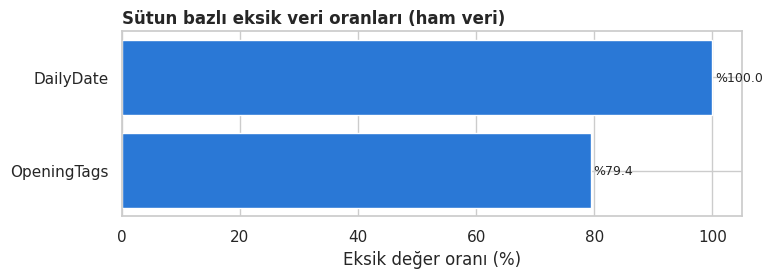

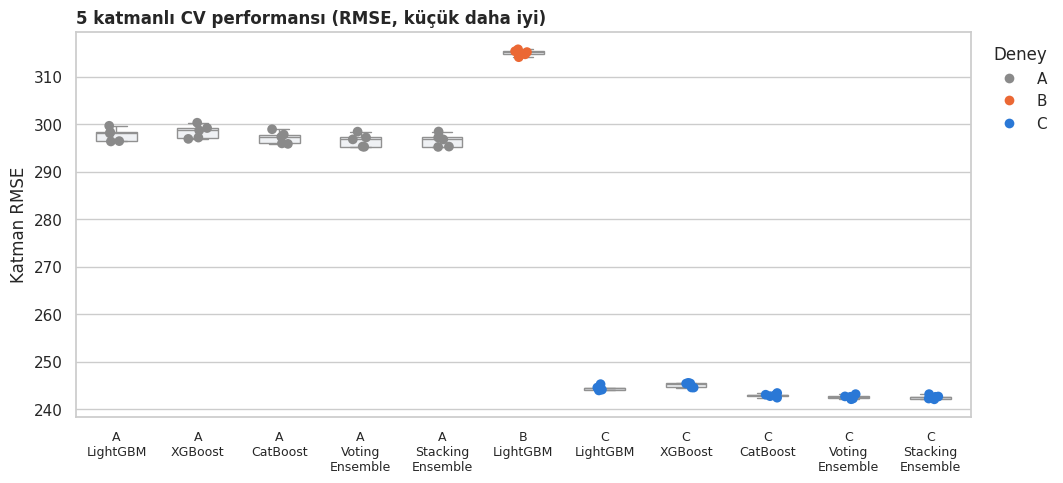

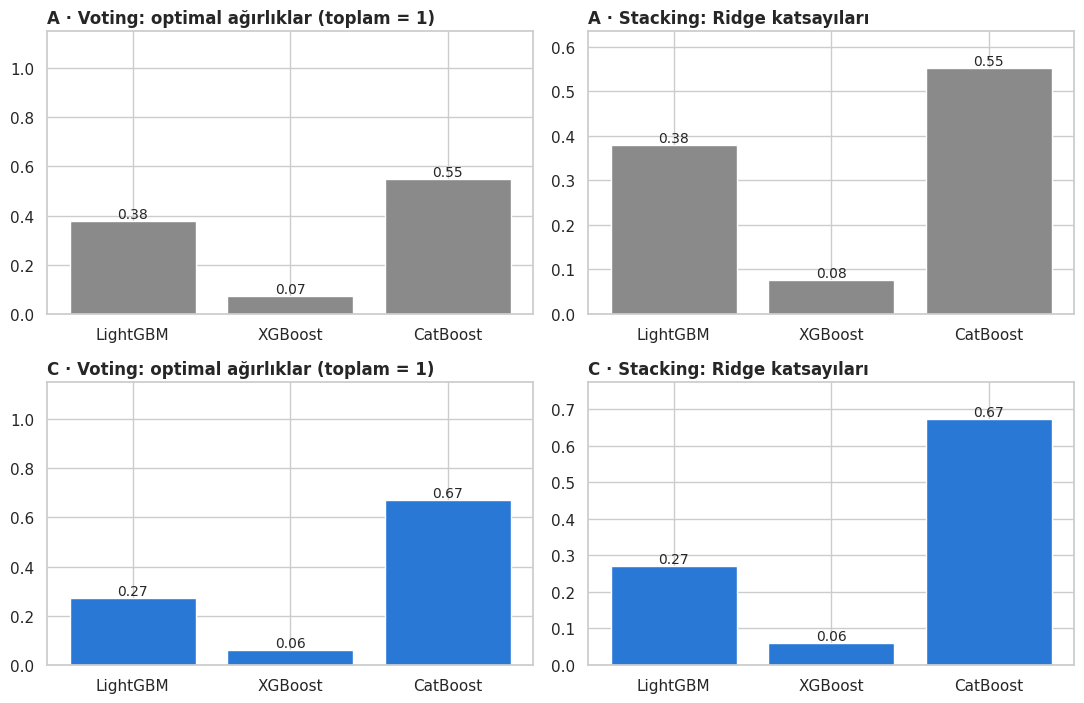

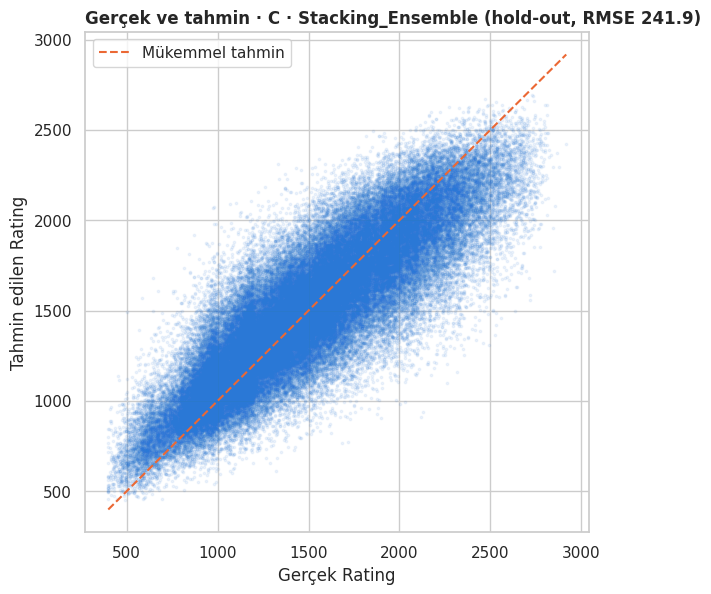

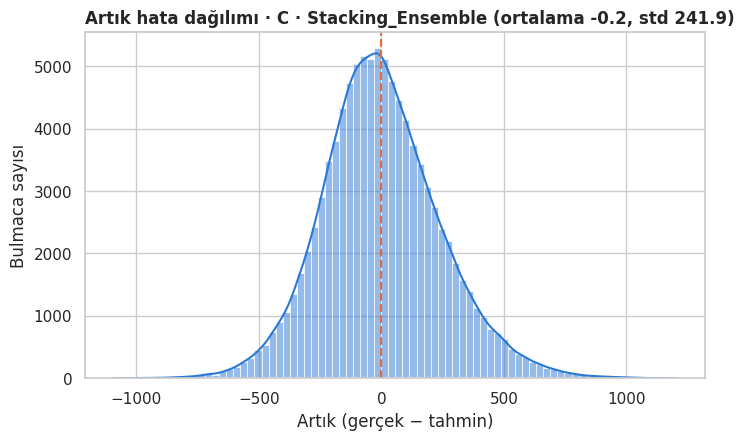

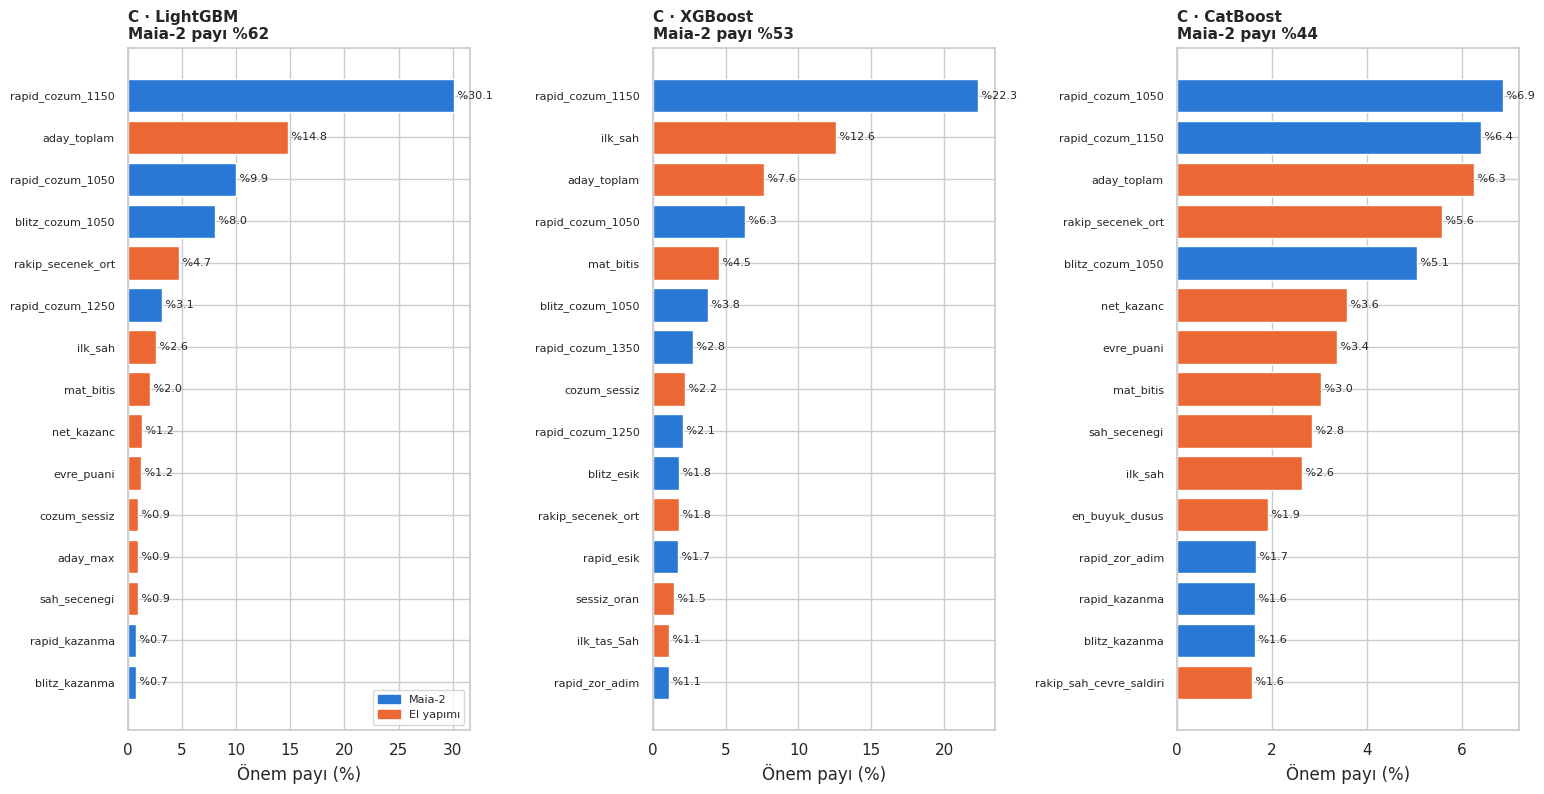

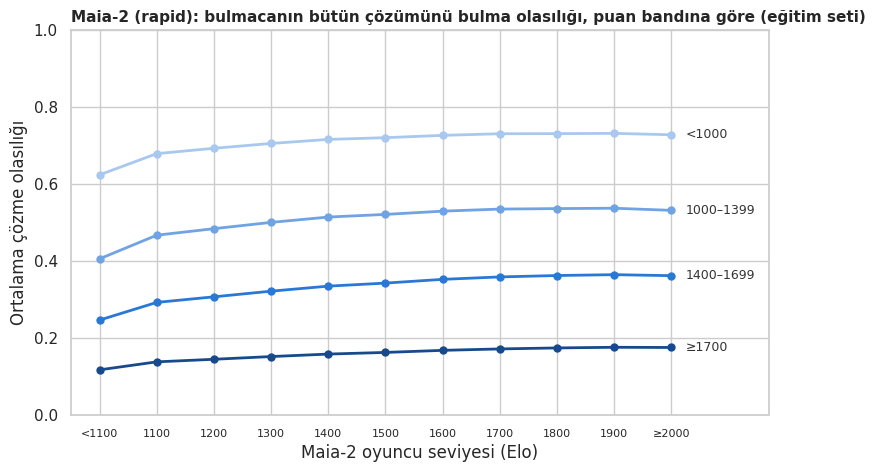

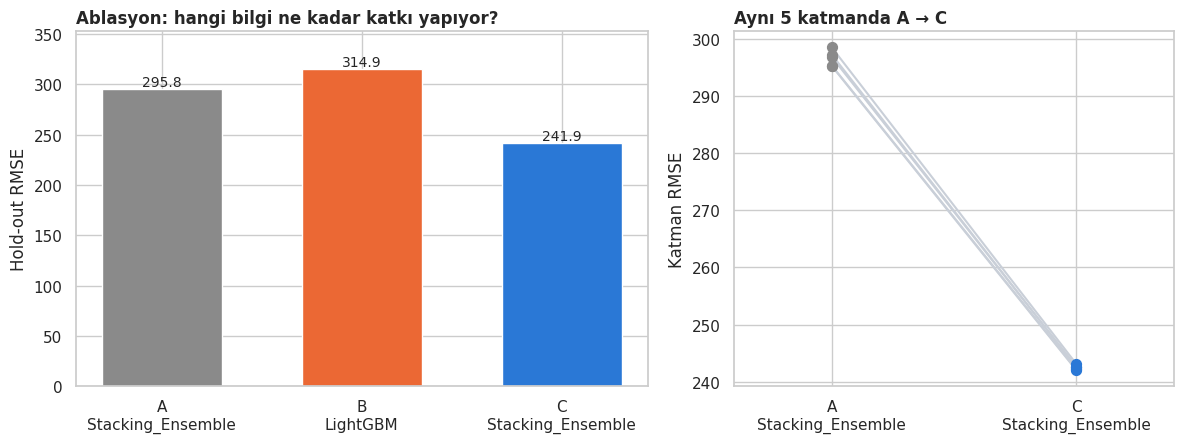

Boru hattı tamamlandı: 78.9 dakika.


In [17]:
SONUC = run_pipeline(df_ham, CFG, goster=True)

## 17. Sonuçlar

In [18]:
print("Liderlik tablosu (CV skoruna göre sıralı; /kaggle/working/leaderboard.csv):")
display(SONUC["leaderboard"])

if SONUC["bantlar"] is not None:
    print("Hold-out RMSE — puan bantlarına göre:")
    display(SONUC["bantlar"])

print("CV skoruna göre her deneyin seçilen modeli:", ", ".join(f"{k} → {v}" for k, v in SONUC["secilen"].items()))
print("\nEşleştirilmiş karşılaştırmalar (yeni − referans; RMSE'de negatif = yeni daha iyi):")
display(SONUC["karsilastirma"])

print("\nKullanılan parametreler:")
display(pd.DataFrame({m: {"Kaynak": SONUC["param_kaynagi"][m] if not CFG.RETUNE else f"Optuna ({CFG.N_TRIALS} deneme)",
                          "Parametreler": ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}"
                                                    for k, v in SONUC["sonuclar"][f"C · {m}"]["best_params"].items()),
                          "C · ağaç sayısı (katman ort.)": int(np.mean(SONUC["sonuclar"][f"C · {m}"]["best_iterations"]))}
                      for m in CFG.MODELS}).T.style.set_properties(subset=["Parametreler"], **{"text-align": "left"}))

maia = set(SONUC["gruplar"]["maia"])
print("C deneyinde Maia-2 özniteliklerinin toplam önem payı:",
      ", ".join(f"{m} %{100 * SONUC['onemler'][m][[i in maia for i in SONUC['onemler'].index]].sum():.0f}" for m in CFG.MODELS))

print("\nSızıntı denetim raporu:")
display(SONUC["auditor"].rapor())

Liderlik tablosu (CV skoruna göre sıralı; /kaggle/working/leaderboard.csv):


,Deney,Öznitelik,CV RMSE,CV ort,CV std,Test RMSE,Test MSE,Test MAE,Test R2
Model,,,,,,,,,
C · Stacking_Ensemble,C,99,242.539 ± 0.379,242.5394,0.3788,241.9188,58524.6995,188.0283,0.7416
C · Voting_Ensemble,C,99,242.549 ± 0.373,242.5495,0.3729,241.9371,58533.5478,188.1346,0.7416
C · CatBoost,C,99,242.907 ± 0.328,242.9075,0.3279,241.9989,58563.4495,188.1527,0.7415
C · LightGBM,C,99,244.465 ± 0.458,244.4649,0.4579,242.9913,59044.7623,189.0301,0.7393
C · XGBoost,C,99,245.080 ± 0.437,245.0800,0.4372,243.5175,59300.7665,189.4770,0.7382
A · Stacking_Ensemble,A,37,296.571 ± 1.223,296.5710,1.2233,295.7515,87468.9395,232.4165,0.6139
A · Voting_Ensemble,A,37,296.576 ± 1.210,296.5756,1.2099,295.7764,87483.6595,232.5619,0.6138
A · CatBoost,A,37,297.161 ± 1.163,297.1606,1.1625,296.0765,87661.2643,232.8594,0.6130
A · LightGBM,A,37,297.759 ± 1.246,297.7587,1.2458,296.3337,87813.6892,232.8286,0.6123


Hold-out RMSE — puan bantlarına göre:


Hold-out RMSE,Genel,<1000,1000–1399,1400–1699,≥1700
Temel (Ortalama),475.9,679.2,320.0,99.0,592.5
A · LightGBM,296.3,268.7,271.8,241.4,353.6
A · XGBoost,296.9,270.0,271.7,241.8,354.3
A · CatBoost,296.1,270.0,270.4,240.2,353.9
A · Voting_Ensemble,295.8,269.2,270.6,240.2,353.3
A · Stacking_Ensemble,295.8,268.1,271.4,241.7,352.5
B · LightGBM,314.9,354.5,280.7,245.4,357.0
C · LightGBM,243.0,222.4,218.8,218.8,282.6
C · XGBoost,243.5,224.1,219.3,218.3,283.2
C · CatBoost,242.0,222.1,218.0,216.7,281.7


CV skoruna göre her deneyin seçilen modeli: A → A · Stacking_Ensemble, B → B · LightGBM, C → C · Stacking_Ensemble

Eşleştirilmiş karşılaştırmalar (yeni − referans; RMSE'de negatif = yeni daha iyi):


,Referans,Yeni,CV fark (RMSE),Yeninin daha iyi olduğu katman,Test fark (RMSE),%95 güven aralığı,Anlamlı mı?,Test MSE farkı
0,A · Stacking_Ensemble,C · Stacking_Ensemble,-54.032,5/5,-53.833,"[-54.947, -52.745]",Evet,-28944.2
1,A · CatBoost,C · CatBoost,-54.253,5/5,-54.078,"[-55.210, -53.010]",Evet,-29097.8
2,A · LightGBM,B · LightGBM,17.245,0/5,18.581,"[16.874, 20.136]",Evet,11357.6
3,C · Voting_Ensemble,C · Stacking_Ensemble,-0.010,4/5,-0.018,"[-0.033, -0.004]",Evet,-8.8



Kullanılan parametreler:


,Kaynak,Parametreler,C · ağaç sayısı (katman ort.)
LightGBM,v2 checkpoint (kesin değerler),"num_leaves=66, min_child_samples=157, subsample=0.9935, subsample_freq=1, colsample_bytree=0.8983, reg_alpha=0.9311, reg_lambda=0.5191",2311
XGBoost,v2 checkpoint (kesin değerler),"max_depth=7, min_child_weight=3.083, subsample=0.8378, colsample_bytree=0.7941, reg_alpha=0.004166, reg_lambda=6.597, gamma=0.001428",2062
CatBoost,v2 checkpoint (kesin değerler),"depth=8, l2_leaf_reg=7.339, random_strength=0.2261, bootstrap_type=Bernoulli, subsample=0.8384",5314


C deneyinde Maia-2 özniteliklerinin toplam önem payı: LightGBM %62, XGBoost %53, CatBoost %44

Sızıntı denetim raporu:


,Durum
Hold-out,"Eğitim 400,000 / Test 100,000; kesişim yok"
Sütunlar,99 öznitelik; yasaklı sütun yok
Sonlu değerler · eğitim,98 sayısal sütunda ±sonsuz yok
Sonlu değerler · test,98 sayısal sütunda ±sonsuz yok
OOF · Temel,"400,000 tahmin; NaN yok"
v2 yeniden kullanım · LightGBM,✓ 5 katman skoru birebir eşleşti (aynı satırla...
OOF · A · LightGBM,"400,000 tahmin; NaN yok"
v2 yeniden kullanım · XGBoost,✓ 5 katman skoru birebir eşleşti (aynı satırla...
OOF · A · XGBoost,"400,000 tahmin; NaN yok"
v2 yeniden kullanım · CatBoost,✓ 5 katman skoru birebir eşleşti (aynı satırla...


In [19]:
# Literatürle bağlam (MSE). Test setleri farklı olduğu için sayılar doğrudan karşılaştırılamaz; büyüklük sırası için verilir.
if not CFG.is_clf:
    lb = SONUC["leaderboard"]
    literatur = pd.DataFrame([
        ("Björkqvist (2025) — tam model", "Lichess, dağılım içi 50 bin test", 35_400),
        ("Björkqvist (2025) — ince ayarlı Maia-2 olmadan", "aynı test", 52_600),
        ("FedCSIS 2025 birincisi", "yarışma final testi (yeni bulmacalar)", 52_300),
        ("IEEE BigData Cup 2024 birincisi", "yarışma final testi (yeni bulmacalar)", 104_540),
        (f"Bu çalışma — v2 ({SONUC['secilen']['A']})", "Lichess, dağılım içi 100 bin test", lb.loc[SONUC["secilen"]["A"], "Test MSE"]),
        (f"Bu çalışma — v3 ({SONUC['secilen']['C']})", "aynı test", lb.loc[SONUC["secilen"]["C"], "Test MSE"]),
    ], columns=["Çalışma", "Test seti", "MSE"]).set_index("Çalışma")
    literatur["RMSE"] = np.sqrt(literatur["MSE"]).round(1)
    literatur["MSE"] = literatur["MSE"].round(0).astype(int)
    display(literatur)

,Test seti,MSE,RMSE
Çalışma,,,
Björkqvist (2025) — tam model,"Lichess, dağılım içi 50 bin test",35400,188.1
Björkqvist (2025) — ince ayarlı Maia-2 olmadan,aynı test,52600,229.3
FedCSIS 2025 birincisi,yarışma final testi (yeni bulmacalar),52300,228.7
IEEE BigData Cup 2024 birincisi,yarışma final testi (yeni bulmacalar),104540,323.3
Bu çalışma — v2 (A · Stacking_Ensemble),"Lichess, dağılım içi 100 bin test",87469,295.8
Bu çalışma — v3 (C · Stacking_Ensemble),aynı test,58525,241.9


## 18. Yorumlama rehberi ve sonraki adım
**Okurken dikkat:**
- **A satırları v2 ile aynı olmalı** (v2 çıktısı eklendiyse birebir; yeniden eğitildiyse çok yakın). Değilse bölme farklıdır; denetim raporundaki "v2 yeniden kullanım" satırına bakın.
- **Ana iddia** karşılaştırma tablosunun ilk satırı: A → C farkının güven aralığı sıfırı içermiyorsa Maia-2 katkısı istatistiksel olarak anlamlıdır.
- **B (sadece Maia-2) A'dan iyiyse:** Hiç satranç bilgisi kodlamadan, yalnızca "insanlar bu hamleyi oynar mı?" sorusunun cevabı 37 elle tasarlanmış öznitelikten daha bilgilidir. Literatür bu sonucu bekletiyor.
- **Bant tablosu:** Maia-2'nin asıl katkısının ≥ 1700 bandında olması beklenir: el yapımı öznitelikler zor bulmacaları birbirinden ayıramıyordu.
- **Maia-2 çözme eğrileri (Grafik 6):** Puan bandı yükseldikçe eğriler aşağı kaymalı. Eğriler birbirine yakınsa Maia-2'nin ayırt ediciliği düşüktür.
- **Öznitelik önemi:** Maia-2 payı yüksek ama el yapımı öznitelikler de listede kalıyorsa iki bilgi kaynağı birbirini tamamlıyor demektir.

**Literatürle karşılaştırma:** Björkqvist'in tam modeli (35,4 bin MSE) Maia-2'yi bulmaca puanlarıyla **ince ayar** yapıyor ve motor öznitelikleri de kullanıyor. Biz Maia-2'yi dondurulmuş olarak, yalnızca olasılık okuyarak kullanıyoruz. Bu yüzden aradaki fark, ince ayar ve motor özniteliklerinin katkısına yakındır.

**Sonraki adım: literatüre katkı.** Yarışmalardan sonra yayımlanan **Maia-3** (Chessformer, ICLR 2026) henüz bu problemde denenmedi. Aynı boru hattında Maia-2 öznitelikleri Maia-3 ile değiştirilip / eklenip A–B–C ablasyonu tekrarlanırsa ölçülebilir ve yeni bir sonuç elde edilir. Diğer adaylar: Stockfish öznitelikleri (doğru hamlenin bulunduğu arama derinliği, en iyi iki hamle arasındaki değer farkı) ve tüm güvenilir bulmacalarla (~4,7 milyon) öğrenme eğrisi.

**Kaynaklar:** Lichess Open Database – Puzzles · Glickman, *Glicko-2* · Tang vd. (2024), *Maia-2: A Unified Model for Human-AI Alignment in Chess* · IEEE BigData Cup 2024 ve FedCSIS 2025 "Predicting Chess Puzzle Difficulty" yarışmaları · Björkqvist (2025), *Estimating the Difficulty of Chess Puzzles by Combining Fine-Tuned Maia-2 with Hand-Crafted and Engine Features* · Miłosz, Kapusta (2024) · Schütt, Huber, André (2024) · Cen vd. (2025).